# Phishing IA — expliqué simplement

## 1. C’est quoi ?
Le **phishing** (hameçonnage), c’est une **arnaque par message** (email, SMS, WhatsApp, etc.).  
L’attaquant se fait passer pour quelqu’un de confiance : banque, collègue, support IT, service de livraison, administration…

## 2. Quel est l’objectif de l’attaquant ?
L’objectif est de te faire faire une action qui lui profite, par exemple :
- **Voler tes identifiants** : mot de passe, code, compte.
- **Voler de l’argent** : faux paiement, faux virement.
- **Installer un malware** : via un lien ou une pièce jointe.
- **Entrer dans l’entreprise** : récupérer un accès pour aller plus loin.

## 3. Comment fonctionne la logique (étape par étape)
1. **Appât** : l’attaquant envoie un message crédible. Ex. : « Votre compte sera bloqué », « Facture urgente ».
2. **Pression** : il crée l’urgence ou la peur pour que tu agisses vite sans vérifier.
3. **Piège** : le message contient un lien, une pièce jointe, ou demande une information sensible.
4. **Action de la victime** : tu cliques, ouvres, réponds, ou donnes tes informations.
5. **Résultat** : l’attaquant récupère ce qu’il voulait (accès, argent, données).

## 4. Exemple concret
> « Votre compte sera désactivé dans 1 heure. Cliquez ici pour vérifier. »

- Tu cliques sur le lien.
- Tu arrives sur un faux site qui ressemble au vrai.
- Tu entres ton mot de passe.
- L’attaquant récupère ton mot de passe.

## 5. Pourquoi l’IA rend le phishing plus difficile à repérer
Avant : fautes, texte bizarre, message générique.  
Avec l’IA, un message peut être bien écrit, personnalisé, adapté au ton d’un collègue/service, donc plus crédible. Les anciens signes seuls ne suffisent plus.

## 6. Lien avec le projet (logique du modèle)
Le modèle ne « lit » pas comme un humain. Il regarde des **signaux/variables** et combine ces signaux pour estimer une probabilité : **malveillant (Oui)** ou **normal (Non)**.  
C’est une **aide à la décision** : un humain doit vérifier avant de bloquer/supprimer.


## 0. Origine et nature des données

**Jeu de données synthétique** généré localement pour ce mini-projet (ISCAE Master VIC). Il ne contient **aucun vrai e-mail, aucune donnée personnelle et aucune source externe** à citer. Les performances mesurées ici ne doivent donc **pas** être présentées comme des résultats obtenus sur de vraies campagnes de phishing.

**Avertissement** : prototype d'aide au pré-dépistage. Le modèle signale un message à **vérifier** ; il ne supprime rien automatiquement. **Validation humaine obligatoire.**

## Notre objectif : pré-dépistage

Dans ce projet, le modèle fait du **pré-dépistage** : il trie rapidement les messages pour repérer ceux qui sont suspects.

- **Entrée** : les signaux du message (urgence, liens, âge du domaine, expéditeur connu, etc.).
- **Sortie** : `Oui` (suspect/malveillant) ou `Non` (normal), avec une probabilité.
- **Exemple** : `urgence_score=9`, `nb_liens=5`, `domaine_age_jours=3`, `expediteur_connu=0`, `piece_jointe=1` → le modèle peut prédire **Oui**.

Le résultat est une **aide à la décision**. La vérification finale reste humaine.


## Comment choisir un modèle ?

### 1. Le contexte
On veut détecter les messages **malveillants (phishing IA)**. Les classes sont déséquilibrées (377 Non / 147 Oui). L’erreur la plus grave est le **Faux Négatif** : un message malveillant prédit `Non`.

### 2. Sur quelle base on choisit ?
- **F1 macro** : critère principal ici, car il donne du poids aux deux classes malgré le déséquilibre.
- **Rappel de la classe Oui** : très important en sécurité, car il mesure combien de malveillants on détecte.
- **Précision / FP** : à surveiller pour éviter trop de fausses alertes.
- **Matrice de confusion** : montre FN/FP en nombres concrets.
- **Simplicité/interprétabilité** : utile pour expliquer la décision à un humain.

### 3. Modèles comparés
| Modèle | Intérêt | Limite |
|---|---|---|
| Régression logistique | Simple, interprétable | Peut rater des relations non linéaires |
| Random Forest | Bon sur relations non linéaires, robuste | Moins simple à expliquer |
| SVM noyau RBF | Marge maximale, très stable en validation croisée | Moins interprétable, plus lent |

### 4. Notre choix
On compare les modèles sur le **même test**. On retient le modèle avec le meilleur compromis, en priorité **F1 macro / Rappel Oui** (moins de FN), tout en gardant une validation humaine. Le modèle retenu dans ce projet est indiqué par les résultats et `model_meta.json`.


# Mini-projet 3 — Veille stratégique : IA et confiance numérique
## Notebook dédié — Phishing assisté par l'IA

**ISCAE — Master VIC | Analyse exploratoire, préparation et classification Machine Learning**

Ce notebook travaille **uniquement** sur `dataset_phishing_ia - dataset_phishing_ia.csv`.
Les cas désinformation et Shadow IA ont chacun leur notebook dédié.

### 1) Contexte général
L'IA générative écrit des messages de phishing sans fautes et avec un ton personnalisé. Les signes
classiques (fautes de langue, style maladroit) deviennent donc moins fiables. Un responsable
sécurité (RSSI) doit pourtant décider, parmi les messages reçus, lesquels méritent une analyse
approfondie. Les 524 lignes du fichier sont **synthétiques** : aucune donnée personnelle, aucun
vrai e-mail.

### 2) Problématique
> **Comment détecter un message malveillant quand les signes classiques deviennent moins fiables
> à cause de l'IA, et comment garder un niveau d'alerte explicable ?**

La cible `message_malveillant` est binaire (`Non` / `Oui`), avec 377 `Non` pour 147 `Oui` :
les classes sont **déséquilibrées**. L'accuracy seule est trompeuse (prédire toujours `Non`
donne déjà ~72 %) : on regarde surtout le **rappel** et le **F1** de la classe `Oui`.

### 3) Quelle erreur coûte le plus cher ?
Le **faux négatif** : un message malveillant classé `Non` passe les filtres et peut déclencher
une compromission. Le faux positif (message légitime signalé) coûte du temps à l'analyste mais
se corrige par validation humaine. On peut donc **baisser le seuil de décision** pour gagner en
rappel, en acceptant plus de faux positifs — ce compromis est étudié plus bas.

Exécuter les cellules dans l'ordre, de haut en bas.

## 0. Installation et importation des bibliothèques
Installer une seule fois les bibliothèques si nécessaire.

In [209]:
# Dans un terminal Jupyter si les bibliothèques ne sont pas installées :
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Bibliothèques chargées avec succès.")

Bibliothèques chargées avec succès.


## 1. Lecture du fichier — dataset unique : Phishing IA

Le CSV doit être dans le même dossier que ce notebook. Les constantes ci-dessous pointent
directement sur le seul fichier utilisé ; il n'y a plus de choix à faire.

## 1. Lecture du fichier

Le notebook utilise directement le dataset phishing IA présent dans le même dossier.


In [210]:
# Chargement du dataset
import pandas as pd

df_brut = pd.read_csv('dataset_phishing_ia - dataset_phishing_ia.csv')
TARGET = 'message_malveillant'
ORDER = ['Non', 'Oui']

print('Dimensions (lignes, colonnes) :', df_brut.shape)


Dimensions (lignes, colonnes) : (524, 11)


In [211]:
# Dernières lignes
df_brut.tail()


,date,heure_envoi,longueur_message,nb_liens,urgence_score,domaine_age_jours,fautes_langue,expediteur_connu,piece_jointe,personnalisation_score,message_malveillant
519,2026-09-29,5,222,1,4,5874.0,1,0,0,6,Non
520,2026-09-30,10,475,4,10,41.0,4,0,0,7,Oui
521,2026-09-30,6,107,0,10,661.0,2,1,1,6,Non
522,2026-09-30,14,509,0,4,1227.0,2,1,0,5,Non
523,2026-09-30,21,507,1,4,800.0,3,0,1,5,Non


In [212]:
# Colonnes
df_brut.columns.tolist()


['date',
 'heure_envoi',
 'longueur_message',
 'nb_liens',
 'urgence_score',
 'domaine_age_jours',
 'fautes_langue',
 'expediteur_connu',
 'piece_jointe',
 'personnalisation_score',
 'message_malveillant']

In [213]:
# Informations générales
df_brut.info()


<class 'pandas.DataFrame'>
RangeIndex: 524 entries, 0 to 523
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    524 non-null    str    
 1   heure_envoi             524 non-null    int64  
 2   longueur_message        524 non-null    int64  
 3   nb_liens                524 non-null    int64  
 4   urgence_score           524 non-null    int64  
 5   domaine_age_jours       514 non-null    float64
 6   fautes_langue           524 non-null    int64  
 7   expediteur_connu        524 non-null    int64  
 8   piece_jointe            524 non-null    int64  
 9   personnalisation_score  524 non-null    int64  
 10  message_malveillant     524 non-null    str    
dtypes: float64(1), int64(8), str(2)
memory usage: 45.2 KB


In [214]:
# Dictionnaire des variables (signification métier)
SIGNIFICATIONS = {
    "date": "Date de réception — exclue du modèle (variable calendaire sans rôle métier).",
    "heure_envoi": "Heure d'envoi (0-23) : un envoi nocturne est plus suspect.",
    "longueur_message": "Nombre de caractères du message.",
    "nb_liens": "Nombre de liens intégrés : chaque lien augmente le risque.",
    "urgence_score": "Score 0-10 de pression temporelle (« agissez maintenant »).",
    "domaine_age_jours": "Ancienneté du domaine en jours (10 valeurs manquantes) : un domaine récent est suspect.",
    "fautes_langue": "Nombre de fautes de langue — signe classique, mais moins fiable avec l'IA.",
    "expediteur_connu": "1 = expéditeur déjà connu, 0 = inconnu.",
    "piece_jointe": "1 = pièce jointe présente, 0 = absente.",
    "personnalisation_score": "Score 0-10 de personnalisation du message (l'IA sait mieux imiter un collègue).",
    "message_malveillant": "CIBLE : Non / Oui. Jamais utilisée comme variable explicative.",
}
dictionnaire = pd.DataFrame({
    "variable": df_brut.columns,
    "type": [str(df_brut[c].dtype) for c in df_brut.columns],
    "valeurs_manquantes": [df_brut[c].isna().sum() for c in df_brut.columns],
    "valeurs_uniques": [df_brut[c].nunique(dropna=True) for c in df_brut.columns],
    "exemples": [str(df_brut[c].dropna().unique()[:5].tolist()) for c in df_brut.columns],
    "signification_metier": [SIGNIFICATIONS.get(col, "À préciser") for col in df_brut.columns],
})
dictionnaire


,variable,type,valeurs_manquantes,valeurs_uniques,exemples,signification_metier
0,date,str,0,231,"['2026-01-01', '2026-01-03', '2026-01-04', '20...",Date de réception — exclue du modèle (variable...
1,heure_envoi,int64,0,24,"[19, 22, 12, 13, 18]",Heure d'envoi (0-23) : un envoi nocturne est p...
2,longueur_message,int64,0,330,"[709, 303, 246, 355, 235]",Nombre de caractères du message.
3,nb_liens,int64,0,6,"[0, 2, 4, 1, 3]",Nombre de liens intégrés : chaque lien augment...
4,urgence_score,int64,0,11,"[4, 6, 7, 5, 3]",Score 0-10 de pression temporelle (« agissez m...
5,domaine_age_jours,float64,10,425,"[1133.0, 268.0, 138.0, 790.0, 323.0]",Ancienneté du domaine en jours (10 valeurs man...
6,fautes_langue,int64,0,7,"[3, 2, 4, 0, 1]","Nombre de fautes de langue — signe classique, ..."
7,expediteur_connu,int64,0,2,"[0, 1]","1 = expéditeur déjà connu, 0 = inconnu."
8,piece_jointe,int64,0,2,"[0, 1]","1 = pièce jointe présente, 0 = absente."
9,personnalisation_score,int64,0,11,"[8, 6, 4, 3, 0]",Score 0-10 de personnalisation du message (l'I...


In [215]:
print("Statistiques descriptives des variables numériques :")
display(df_brut.describe().T)

print("Statistiques descriptives de toutes les variables :")
display(df_brut.describe(include="all").T)

Statistiques descriptives des variables numériques :


,count,mean,std,min,25%,50%,75%,max
heure_envoi,524.0,12.238550,6.889344,0.0,6.00,13.0,18.00,23.0
longueur_message,524.0,413.225191,162.774765,60.0,301.50,423.0,523.25,896.0
nb_liens,524.0,1.387405,1.165433,0.0,1.00,1.0,2.00,5.0
urgence_score,524.0,4.519084,2.373696,0.0,3.00,4.0,6.00,10.0
domaine_age_jours,514.0,739.330739,761.682914,1.0,217.25,516.0,951.25,5874.0
fautes_langue,524.0,2.020992,1.387440,0.0,1.00,2.0,3.00,6.0
expediteur_connu,524.0,0.440840,0.496962,0.0,0.00,0.0,1.00,1.0
piece_jointe,524.0,0.232824,0.423035,0.0,0.00,0.0,0.00,1.0
personnalisation_score,524.0,4.977099,2.554090,0.0,3.00,5.0,7.00,10.0


Statistiques descriptives de toutes les variables :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,524,231,2026-02-22,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
heure_envoi,524.0,NaN,NaN,NaN,12.23855,6.889344,0.0,6.0,13.0,18.0,23.0
longueur_message,524.0,NaN,NaN,NaN,413.225191,162.774765,60.0,301.5,423.0,523.25,896.0
nb_liens,524.0,NaN,NaN,NaN,1.387405,1.165433,0.0,1.0,1.0,2.0,5.0
urgence_score,524.0,NaN,NaN,NaN,4.519084,2.373696,0.0,3.0,4.0,6.0,10.0
domaine_age_jours,514.0,NaN,NaN,NaN,739.330739,761.682914,1.0,217.25,516.0,951.25,5874.0
fautes_langue,524.0,NaN,NaN,NaN,2.020992,1.38744,0.0,1.0,2.0,3.0,6.0
expediteur_connu,524.0,NaN,NaN,NaN,0.44084,0.496962,0.0,0.0,0.0,1.0,1.0
piece_jointe,524.0,NaN,NaN,NaN,0.232824,0.423035,0.0,0.0,0.0,0.0,1.0
personnalisation_score,524.0,NaN,NaN,NaN,4.977099,2.55409,0.0,3.0,5.0,7.0,10.0


In [216]:
print("Nombre de valeurs distinctes par colonne :")
display(df_brut.nunique().sort_values(ascending=False).to_frame("valeurs_uniques"))

print("Valeurs distinctes de la cible :")
print(df_brut[TARGET].value_counts(dropna=False))



Nombre de valeurs distinctes par colonne :


,valeurs_uniques
domaine_age_jours,425
longueur_message,330
date,231
heure_envoi,24
urgence_score,11
personnalisation_score,11
fautes_langue,7
nb_liens,6
expediteur_connu,2
piece_jointe,2


Valeurs distinctes de la cible :
message_malveillant
Non    377
Oui    147
Name: count, dtype: int64


## 3. Dictionnaire des variables et compréhension métier

Cette cellule affiche un dictionnaire automatique (nom, type, nombre de valeurs manquantes et exemples). Compléter ensuite la colonne « signification métier » avec les descriptions du cahier des charges.

In [217]:
SIGNIFICATIONS = {
    "date": "Date de réception — exclue du modèle (variable calendaire sans rôle métier).",
    "heure_envoi": "Heure d'envoi (0-23) : un envoi nocturne est plus suspect.",
    "longueur_message": "Nombre de caractères du message.",
    "nb_liens": "Nombre de liens intégrés : chaque lien augmente le risque.",
    "urgence_score": "Score 0-10 de pression temporelle (« agissez maintenant »).",
    "domaine_age_jours": "Ancienneté du domaine en jours (10 valeurs manquantes) : un domaine récent est suspect.",
    "fautes_langue": "Nombre de fautes de langue — signe classique, mais moins fiable avec l'IA.",
    "expediteur_connu": "1 = expéditeur déjà connu, 0 = inconnu.",
    "piece_jointe": "1 = pièce jointe présente, 0 = absente.",
    "personnalisation_score": "Score 0-10 de personnalisation du message (l'IA sait mieux imiter un collègue).",
    "message_malveillant": "CIBLE : Non / Oui. Jamais utilisée comme variable explicative.",
}
dictionnaire = pd.DataFrame({
    "variable": df_brut.columns,
    "type": [str(df_brut[c].dtype) for c in df_brut.columns],
    "valeurs_manquantes": [df_brut[c].isna().sum() for c in df_brut.columns],
    "valeurs_uniques": [df_brut[c].nunique(dropna=True) for c in df_brut.columns],
    "exemples": [str(df_brut[c].dropna().unique()[:5].tolist()) for c in df_brut.columns],
    "signification_metier": [SIGNIFICATIONS.get(col, "À préciser") for col in df_brut.columns],
})
display(dictionnaire)

,variable,type,valeurs_manquantes,valeurs_uniques,exemples,signification_metier
0,date,str,0,231,"['2026-01-01', '2026-01-03', '2026-01-04', '20...",Date de réception — exclue du modèle (variable...
1,heure_envoi,int64,0,24,"[19, 22, 12, 13, 18]",Heure d'envoi (0-23) : un envoi nocturne est p...
2,longueur_message,int64,0,330,"[709, 303, 246, 355, 235]",Nombre de caractères du message.
3,nb_liens,int64,0,6,"[0, 2, 4, 1, 3]",Nombre de liens intégrés : chaque lien augment...
4,urgence_score,int64,0,11,"[4, 6, 7, 5, 3]",Score 0-10 de pression temporelle (« agissez m...
5,domaine_age_jours,float64,10,425,"[1133.0, 268.0, 138.0, 790.0, 323.0]",Ancienneté du domaine en jours (10 valeurs man...
6,fautes_langue,int64,0,7,"[3, 2, 4, 0, 1]","Nombre de fautes de langue — signe classique, ..."
7,expediteur_connu,int64,0,2,"[0, 1]","1 = expéditeur déjà connu, 0 = inconnu."
8,piece_jointe,int64,0,2,"[0, 1]","1 = pièce jointe présente, 0 = absente."
9,personnalisation_score,int64,0,11,"[8, 6, 4, 3, 0]",Score 0-10 de personnalisation du message (l'I...


### Comment le modèle prédit-il ? (logique pas à pas)

1. **X et y** : `y = message_malveillant`. `X` = toutes les autres colonnes **sauf `date` et
   `semaine`** (le cahier des charges interdit d'utiliser le calendrier sans justification).
   Un `assert` vérifie que la cible n'est pas dans `X` : c'est la règle anti-fuite n°1.
2. **Prétraitement** : `ColumnTransformer` + `Pipeline` — imputation des 10 valeurs manquantes de
   `domaine_age_jours` par la **médiane du train**, standardisation des variables numériques,
   imputation par le mode puis one-hot pour les catégorielles. Rien n'est calculé sur le test.
3. **Comparaison** : régression logistique (linéaire), Random Forest (arbres) et SVM noyau RBF
   (marge maximale). La baseline majoritaire a été retirée car elle prédit toujours `Non` et ne
   détecte aucune attaque. On choisit le meilleur au **F1 macro**, pas à l'accuracy, à cause du
   déséquilibre 377/147.
4. **Validation croisée** sur le train uniquement (`StratifiedKFold`) pour vérifier la stabilité.
5. **Décision** : `predict_proba` donne `P(Non)` et `P(Oui)` ; la classe prédite est le maximum.
   Pour un scénario saisi dans le formulaire, on peut fixer un **seuil** plus bas que 0,5 sur
   `P(Oui)` : plus de rappel (moins d'attaques manquées), mais plus de faux positifs.
6. **Explication** : permutation importance sur le test → les variables qui comptent le plus
   (`domaine_age_jours`, `urgence_score`, `longueur_message`, `nb_liens`) alimentent l'alerte et
   la recommandation affichée à l'utilisateur.
7. **Validation humaine** : une prédiction `Oui` déclenche une vérification, jamais une suppression
   automatique du message.

## 4. Diagnostic de qualité : valeurs manquantes et doublons

In [218]:
tableau = pd.DataFrame({
    "manquants": df_brut.isna().sum(),
     "% manquants": (df_brut.isna().mean() * 100).round(2)
     })

display(tableau)

nb_doublons = df_brut.duplicated().sum()
print(f"Nombre de lignes dupliquées : {nb_doublons}")
print("Nombre de lignes avant nettoyage :", len(df_brut))

,manquants,% manquants
date,0,0.00
heure_envoi,0,0.00
longueur_message,0,0.00
nb_liens,0,0.00
urgence_score,0,0.00
domaine_age_jours,10,1.91
fautes_langue,0,0.00
expediteur_connu,0,0.00
piece_jointe,0,0.00
personnalisation_score,0,0.00


Nombre de lignes dupliquées : 4
Nombre de lignes avant nettoyage : 524


In [219]:
# Afficher les doublons pour les examiner avant suppression
display(df_brut[df_brut.duplicated(keep=False)].sort_values(by=list(df_brut.columns)).head(20))

,date,heure_envoi,longueur_message,nb_liens,urgence_score,domaine_age_jours,fautes_langue,expediteur_connu,piece_jointe,personnalisation_score,message_malveillant
71,2026-02-02,23,283,2,8,574.0,3,0,0,4,Non
72,2026-02-02,23,283,2,8,574.0,3,0,0,4,Non
224,2026-04-26,18,528,0,5,789.0,0,1,0,9,Non
225,2026-04-26,18,528,0,5,789.0,0,1,0,9,Non
330,2026-06-15,4,397,5,7,278.0,1,1,1,2,Oui
331,2026-06-15,4,397,5,7,278.0,1,1,1,2,Oui
458,2026-08-30,17,377,0,3,627.0,3,1,0,4,Non
459,2026-08-30,17,377,0,3,627.0,3,1,0,4,Non


## 5. Nettoyage des données

Le cahier des charges indique que chaque fichier contient quelques doublons exacts et une colonne numérique avec des valeurs manquantes. On supprime les doublons exacts. Pour les valeurs manquantes, l'imputation par médiane sera faite dans le pipeline, calculée sur le train uniquement : cela évite de transmettre au modèle une information issue du test.

## 3. Nettoyage simple


In [220]:
# Copie de travail
df = df_brut.copy()
print('Lignes avant :', len(df))


Lignes avant : 524


In [221]:
# Suppression des doublons
nb_avant = len(df)
df = df.drop_duplicates().copy()
print('Doublons supprimés :', nb_avant - len(df))
print('Lignes après :', len(df))


Doublons supprimés : 4
Lignes après : 520


In [222]:
# Valeurs manquantes
df.isna().sum().to_frame('manquants')


,manquants
date,0
heure_envoi,0
longueur_message,0
nb_liens,0
urgence_score,0
domaine_age_jours,10
fautes_langue,0
expediteur_connu,0
piece_jointe,0
personnalisation_score,0


In [223]:
# Vérification simple : la colonne à prédire existe
colonne_cible = 'message_malveillant'
if colonne_cible not in df.columns:
    raise ValueError('Colonne à prédire absente : ' + colonne_cible)
if df[colonne_cible].isna().any():
    print('Attention : valeurs manquantes dans la colonne à prédire.')
else:
    print('OK : la colonne à prédire est présente et complète.')


OK : la colonne à prédire est présente et complète.


In [224]:
# Types de données
df.dtypes.to_frame('type')


,type
date,str
heure_envoi,int64
longueur_message,int64
nb_liens,int64
urgence_score,int64
domaine_age_jours,float64
fautes_langue,int64
expediteur_connu,int64
piece_jointe,int64
personnalisation_score,int64


In [225]:
# Répartition de la colonne à prédire
df[colonne_cible].value_counts().to_frame('effectif')


,effectif
message_malveillant,
Non,374
Oui,146


## 6. Analyse exploratoire des données (EDA)

Les graphiques servent à comprendre le phénomène et les données avant de modéliser. Ils ne prouvent pas une relation de causalité.

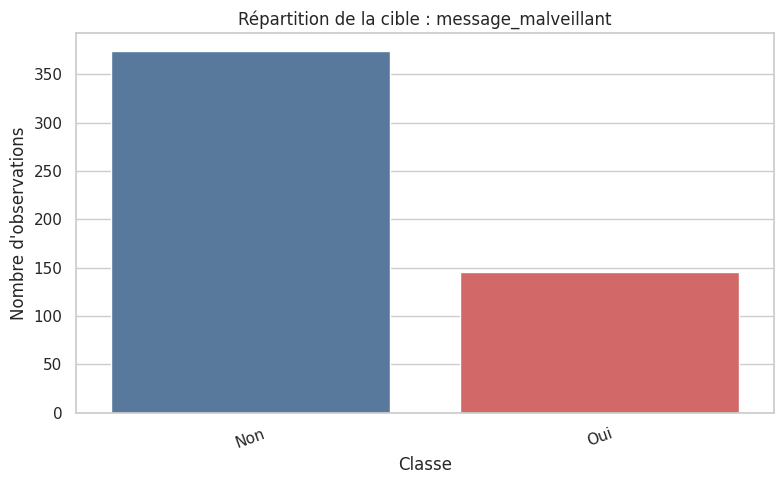

Pourcentage de chaque classe :


,pourcentage_%
message_malveillant,
Non,71.92
Oui,28.08


In [226]:
# Graphique 1 : répartition de la variable cible
plt.figure(figsize=(8, 5))
ordre = df[TARGET].value_counts().index
pct = (df[TARGET].value_counts(normalize=True) * 100)

sns.countplot(data=df, x=TARGET, order=ordre , palette=['#4C78A8','#E45756'])
plt.title(f"Répartition de la cible : {TARGET}")
plt.xlabel("Classe")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

print("Pourcentage de chaque classe :")
display((df[TARGET].value_counts(normalize=True) * 100).round(2).to_frame("pourcentage_%"))

### Interprétation — Histogrammes (variables numériques)

**Axes**
- **Abscisse (axe horizontal, X)** : les **valeurs** de la variable.  
  Exemple : pour `urgence_score`, l’axe X va de 0 à 10. Avec `bins=20`, les valeurs sont regroupées en 20 petites tranches.
- **Ordonnée (axe vertical, Y)** : le **nombre de messages** (effectif) dans chaque tranche.  
  Plus la barre est haute, plus il y a de messages avec cette valeur.

**Utilité** : voir la distribution d’une variable (où les valeurs sont concentrées, étalées, rares/extrêmes).

**Comment lire**
- Barre haute = beaucoup de messages dans cette plage.
- Barre basse = peu de messages.
- Pic = valeur/plage la plus fréquente.
- Valeurs isolées = rares/extrêmes.

**Exemples dataset** : `domaine_age_jours` faible peut signaler domaine récent ; `urgence_score` élevé = pression ; `fautes_langue` souvent faible avec IA.


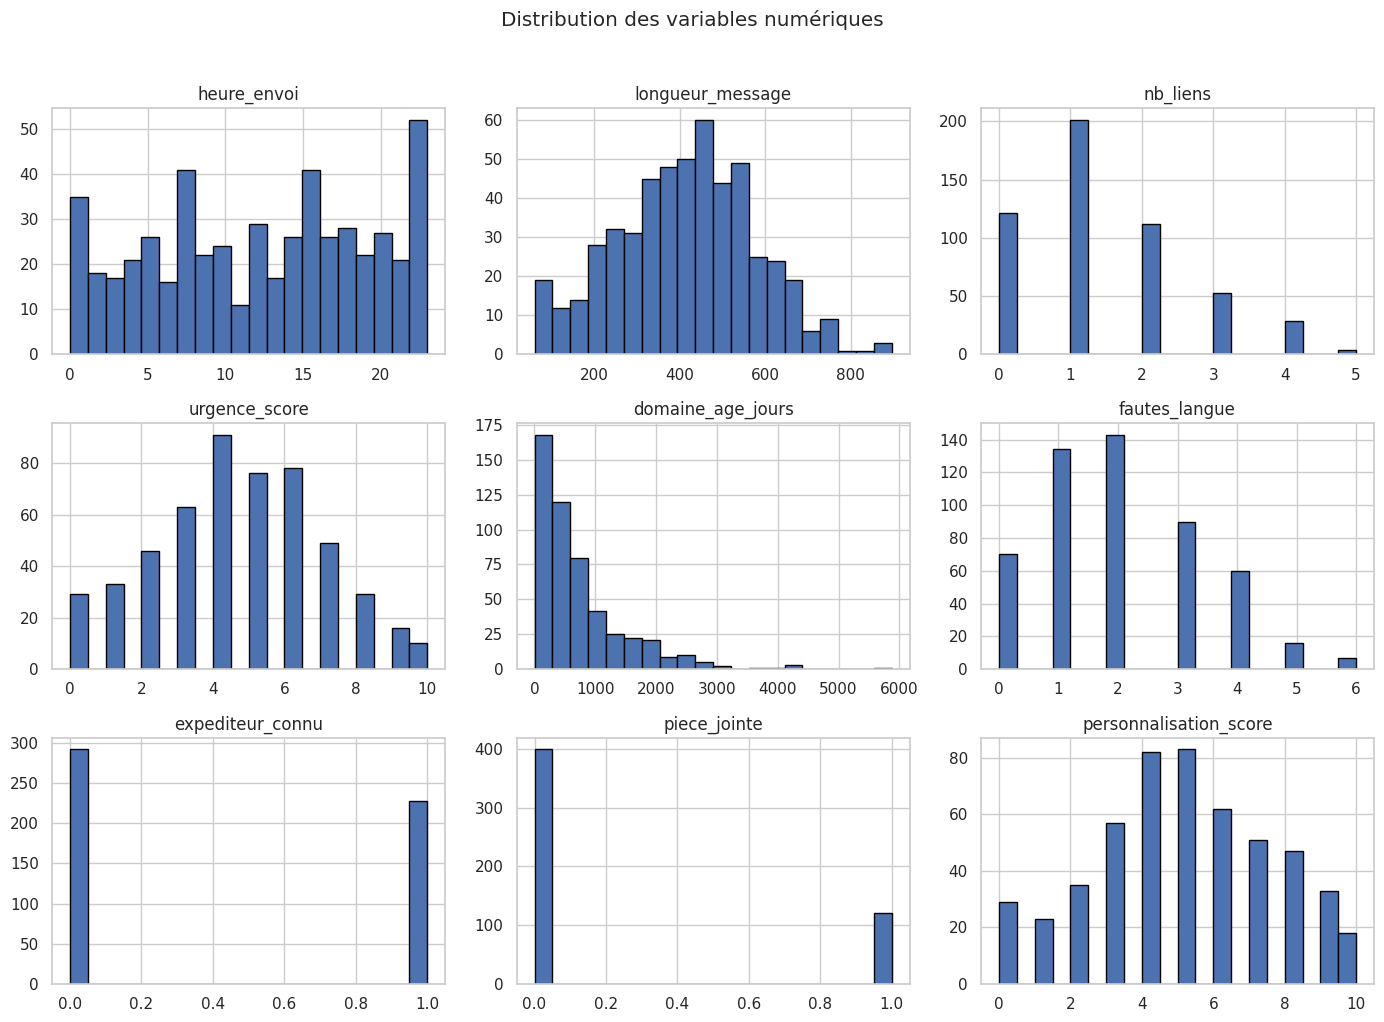

In [227]:
# Graphique 2 : distributions des variables numériques
colonnes_num = df.select_dtypes(include=np.number).columns.tolist()
if colonnes_num:
    df[colonnes_num].hist(figsize=(14, 10), bins=20, edgecolor="black")
    plt.suptitle("Distribution des variables numériques", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Aucune variable numérique.")

### Interprétation des boxplots

| Variable | Ce qu'on voit | Pouvoir discriminant |
|---|---|---|
| `domaine_age_jours` | Médiane d'environ 650 jours pour « Non » contre environ 220 pour « Oui ». La boîte « Oui » est très basse (80 à 500 jours). | Fort |
| `urgence_score` | Médiane de 4 pour « Non » contre 6 pour « Oui ». Le quart inférieur des « Oui » commence à 4, celui des « Non » à 2. | Bon |
| `nb_liens` | Médiane de 1 pour « Non » contre 2 pour « Oui ». Les « Oui » vont de 1 à 3 liens, les « Non » de 0 à 2. | Moyen |
| `longueur_message` | Médiane d'environ 430 caractères pour « Non » contre environ 400 pour « Oui ». Les boîtes se chevauchent presque entièrement. | Faible |
| `heure_envoi` | Médiane de 12 h pour « Non » contre 13 h pour « Oui ». Même étendue (0 à 23 h), boîtes quasi identiques. | Quasi nul |
| `fautes_langue` | Boîtes identiques (médiane 2, de 1 à 3, maximum 6). | Nul |

**Lecture détaillée**

- **Âge du domaine** : un domaine récent est typique du phishing, car les attaquants enregistrent des domaines jetables. C'est la variable qui sépare le mieux. Sa distribution est très asymétrique : les points isolés jusqu'à 5 900 jours chez les « Non » sont de vieux domaines légitimes (16 ans), pas des erreurs. Il faut les garder, utiliser la médiane et envisager une transformation logarithmique.
- **Urgence et liens** : les messages malveillants poussent à agir vite et contiennent plus de liens. Ces deux signaux sont cohérents avec le phishing, mais chacun se chevauche beaucoup avec les messages normaux.
- **Longueur et heure d'envoi** : le décalage est faible, donc ces variables aident peu seules.
- **Fautes de langue** : aucune différence. C'est le résultat le plus intéressant pour un projet « IA et confiance numérique » : les faux messages écrits par une IA sont souvent sans fautes, donc la faute d'orthographe ne permet plus de détecter le phishing. C'est une explication possible ; il faudrait la confirmer avec la façon dont le dataset a été construit.

**Conclusion** : aucune variable ne suffit seule, sauf peut-être l'âge du domaine. Classement : `domaine_age_jours > urgence_score > nb_liens > longueur_message > heure_envoi > fautes_langue`.


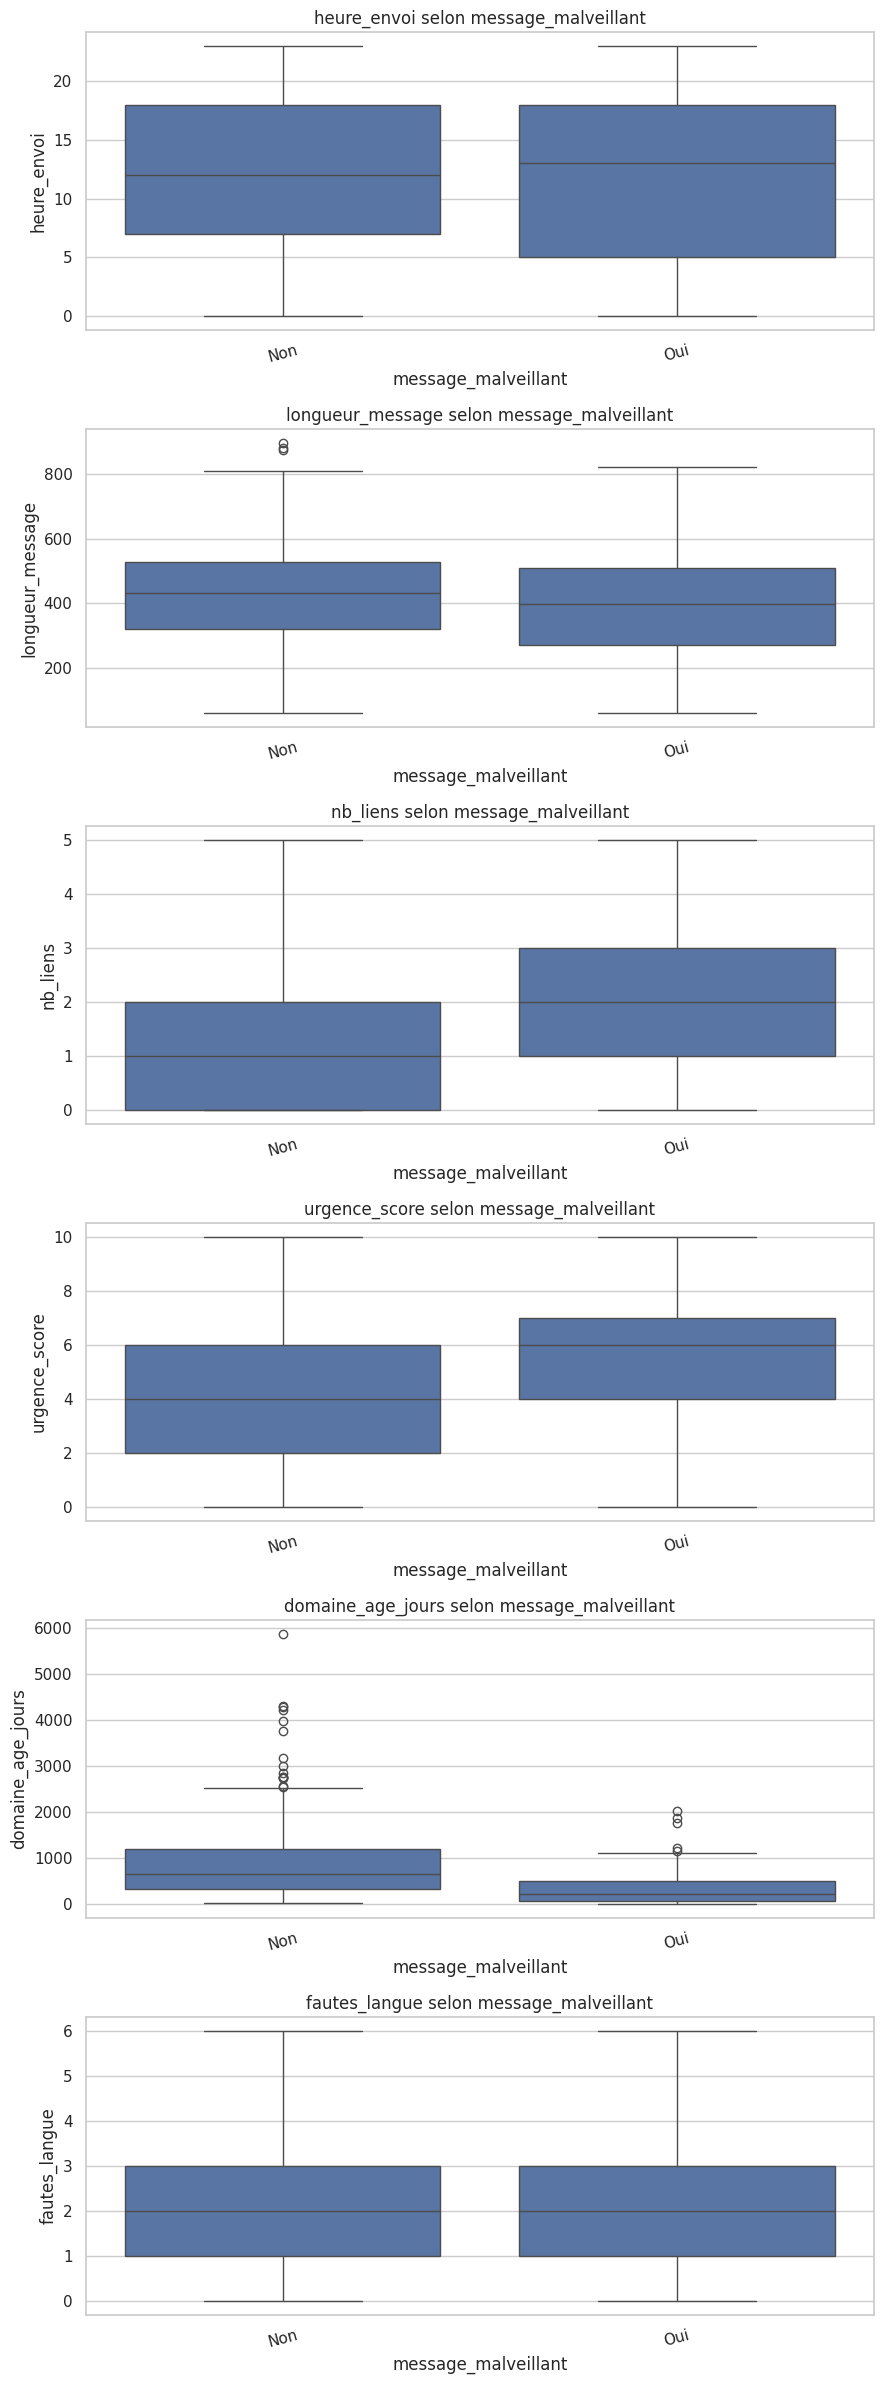

In [228]:
# Graphique 3 : relation entre variables numériques et cible
# Les boxplots sont adaptés à une cible catégorielle.
if colonnes_num:
    nb = min(len(colonnes_num), 6)
    fig, axes = plt.subplots(nb, 1, figsize=(9, 4 * nb))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, colonnes_num[:nb]):
        sns.boxplot(data=df, x=TARGET, y=col, ax=ax)
        ax.set_title(f"{col} selon {TARGET}")
        ax.tick_params(axis="x", rotation=15)
    plt.tight_layout()
    plt.show()

Variables tracées : ['nb_liens', 'urgence_score', 'fautes_langue', 'expediteur_connu', 'piece_jointe', 'personnalisation_score']


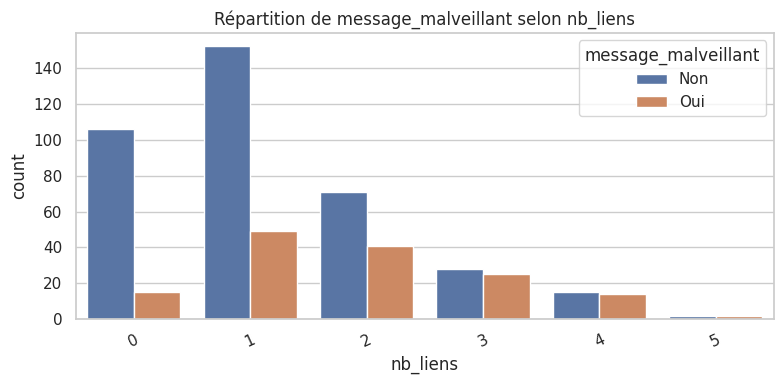

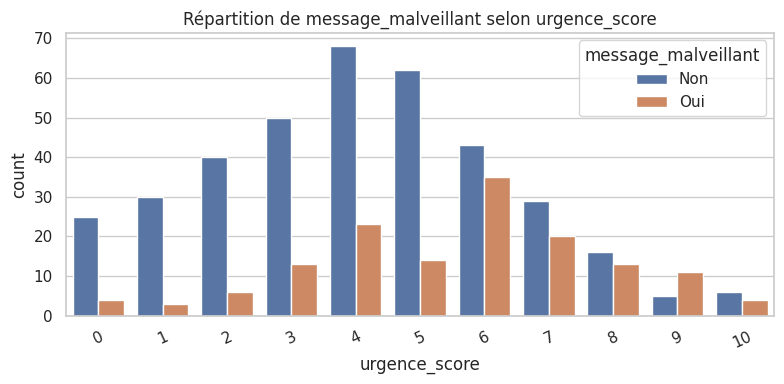

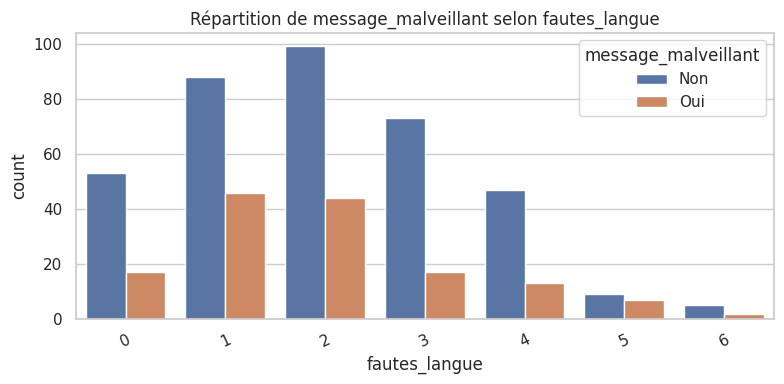

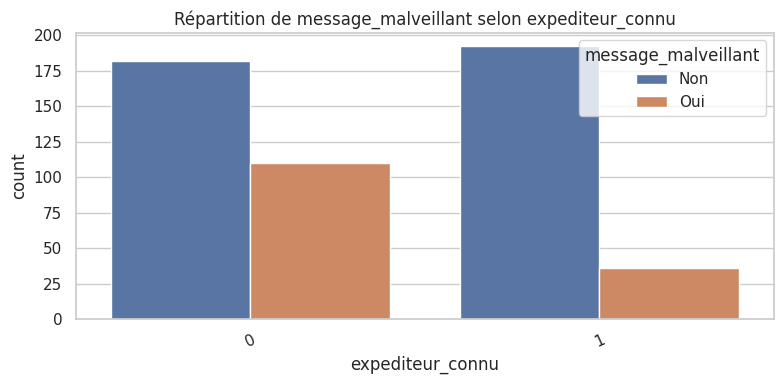

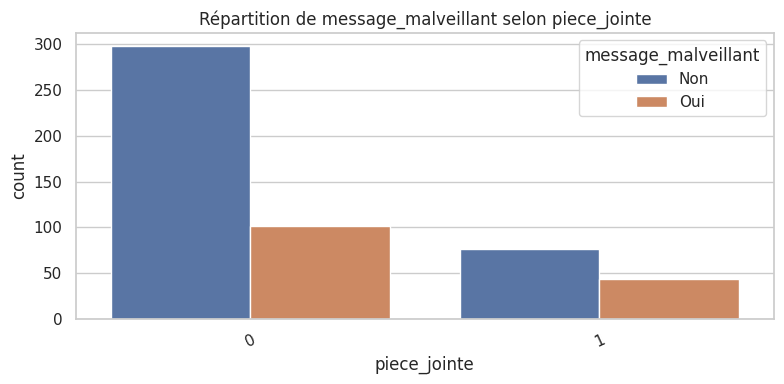

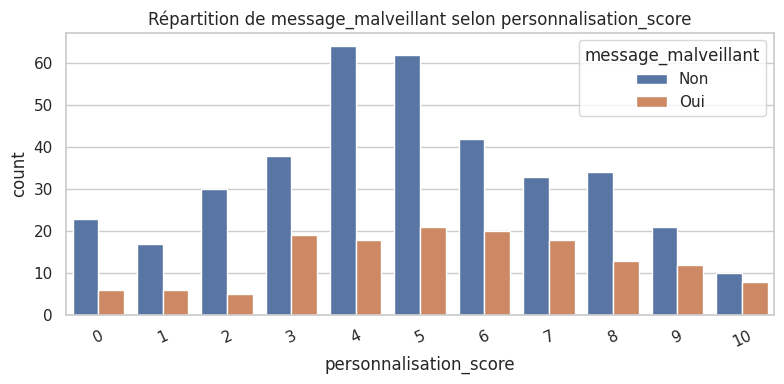

In [229]:
# Colonnes à ignorer (calendrier) et cible
IGNORER = [TARGET, "date", "semaine"]

# 1) Catégorielles (texte)
cols_cat = [c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
            if c not in IGNORER]

# 2) Numériques discrètes (ex. 0/1, scores 0-10, petits compteurs)
cols_discretes = [c for c in df.select_dtypes(include="number").columns
                  if c not in IGNORER and df[c].nunique(dropna=True) <= 15]

cols_a_tracer = [c for c in cols_cat + cols_discretes if df[c].nunique(dropna=True) <= 15]
print("Variables tracées :", cols_a_tracer)

if not cols_a_tracer:
    print("Aucune variable catégorielle ou discrète à tracer.")

for col in cols_a_tracer:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue=TARGET)
    plt.title(f"Répartition de {TARGET} selon {col}")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

## 7. Étude des corrélations et des associations

La corrélation de Pearson mesure une association linéaire entre variables numériques. Elle ne s'applique pas directement aux catégories nominales. On encode temporairement la cible pour visualiser une association exploratoire, mais le code numérique des classes ne doit pas être interprété comme une distance naturelle entre elles. Une corrélation ne signifie pas causalité.

### Comment lire une matrice de corrélation

**1. La structure** : chaque case croise la variable de sa ligne avec celle de sa colonne. La matrice est symétrique (case A,B = case B,A), donc on lit surtout une moitié.

**2. La diagonale** : toujours 1,00 (rouge foncé) car une variable est parfaitement corrélée avec elle-même. On l’ignore.

**3. Le nombre (coefficient de Pearson r, entre -1 et +1)**
- `+1` : quand l’une augmente, l’autre augmente.
- `-1` : quand l’une augmente, l’autre diminue.
- `0` : aucun lien linéaire.
- Repères indicatifs : `|r| < 0,3` faible, `0,3 à 0,7` modérée, `> 0,7` forte.

**4. La couleur** : rouge = positif, bleu = négatif, gris clair = proche de 0. Plus la couleur est intense, plus le lien est fort.

### Ce que montre ton graphique
- Les cases hors diagonale sont gris clair : valeurs réelles entre **-0,060 et +0,067**. Les 9 variables sont donc pratiquement indépendantes.
- Corrélations les plus fortes (mais très faibles) : `expediteur_connu`/`domaine_age_jours` (**+0,067**), `urgence_score`/`expediteur_connu` (**+0,063**), `fautes_langue`/`nb_liens` (**-0,060**).
- Avec la cible (`Oui = 1`), les liens sont plus nets : `domaine_age_jours` **-0,329**, `urgence_score` **+0,272**, `nb_liens` **+0,259**, `expediteur_connu` **-0,242**.
- Cette matrice ne mesure que des liens linéaires : le **SVM RBF** peut capter des interactions non linéaires qu'elle ne montre pas.

### Conclusion
- **Pas de redondance / pas de multicolinéarité forte** : aucune variable n’en duplique une autre, on peut les garder.
- **Chaque variable apporte une information distincte**.
- Cela ne veut pas dire qu’elles sont inutiles pour prédire `message_malveillant` : cette matrice ne contient pas la cible.

### Limites
- **Cible absente** : pour voir le lien avec la malveillance, il faut aussi regarder la relation avec `message_malveillant` (boxplots/moyennes par classe).
- **Pearson = lien linéaire uniquement** ; un lien courbe peut donner `r ≈ 0`.
- **Variables binaires** (`expediteur_connu`, `piece_jointe`) : lecture approximative avec Pearson.
- Une matrice très « vide » peut aussi refléter un dataset synthétique ; à signaler dans les limites si c’est le cas.

> Phrase rapport : « Toutes les corrélations entre variables explicatives sont proches de zéro (|r| ≤ 0,07) : les variables sont indépendantes, sans redondance, et peuvent toutes être conservées pour la modélisation. »


Variables numériques analysées : ['heure_envoi', 'longueur_message', 'nb_liens', 'urgence_score', 'domaine_age_jours', 'fautes_langue', 'expediteur_connu', 'piece_jointe', 'personnalisation_score']


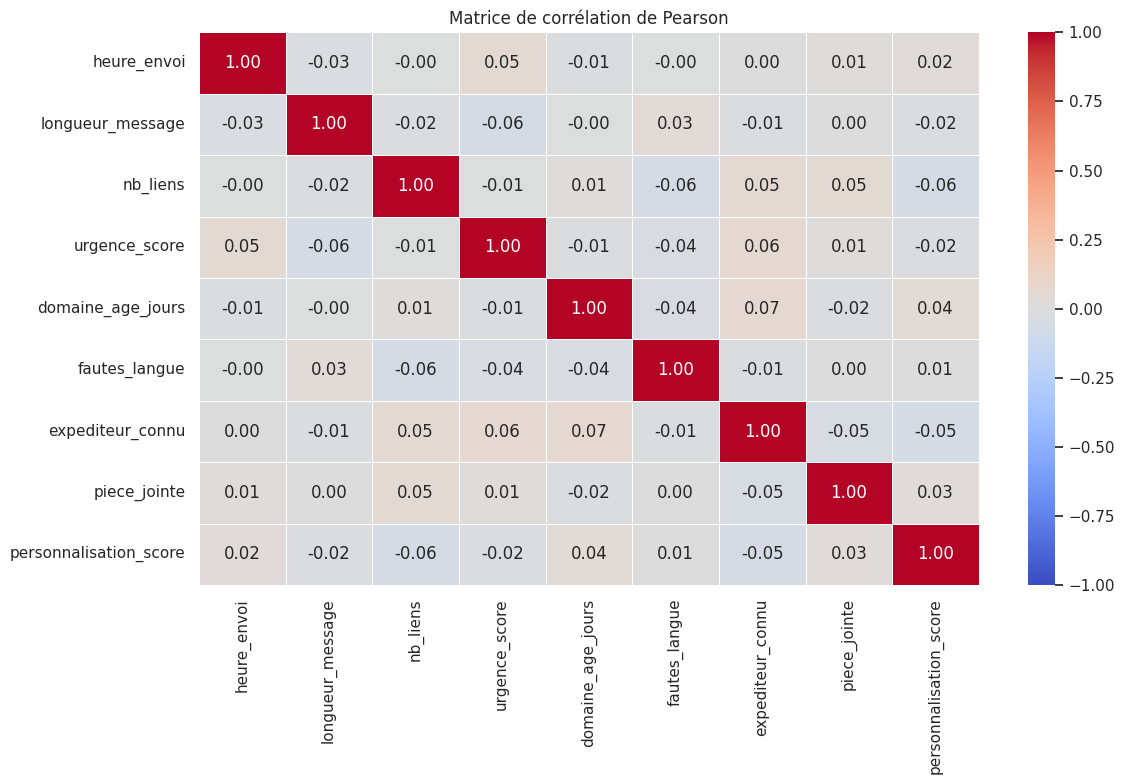

,heure_envoi,longueur_message,nb_liens,urgence_score,domaine_age_jours,fautes_langue,expediteur_connu,piece_jointe,personnalisation_score
heure_envoi,1.000,-0.029,-0.002,0.047,-0.008,-0.004,0.001,0.013,0.024
longueur_message,-0.029,1.000,-0.016,-0.059,-0.001,0.035,-0.008,0.000,-0.022
nb_liens,-0.002,-0.016,1.000,-0.006,0.010,-0.060,0.055,0.049,-0.055
urgence_score,0.047,-0.059,-0.006,1.000,-0.012,-0.036,0.063,0.014,-0.020
domaine_age_jours,-0.008,-0.001,0.010,-0.012,1.000,-0.038,0.067,-0.021,0.042
fautes_langue,-0.004,0.035,-0.060,-0.036,-0.038,1.000,-0.009,0.001,0.008
expediteur_connu,0.001,-0.008,0.055,0.063,0.067,-0.009,1.000,-0.046,-0.055
piece_jointe,0.013,0.000,0.049,0.014,-0.021,0.001,-0.046,1.000,0.030
personnalisation_score,0.024,-0.022,-0.055,-0.020,0.042,0.008,-0.055,0.030,1.000


In [230]:

# Corrélation entre les variables numériques explicatives
# On exclut la cible et les variables calendaires.

IGNORER = [TARGET, "date", "semaine"]

# Sélection des colonnes numériques
num_features_eda = [
    c for c in df.select_dtypes(include="number").columns
    if c not in IGNORER
]

print("Variables numériques analysées :", num_features_eda)

# Vérification du nombre de variables
if len(num_features_eda) >= 2:

    # Calcul de la corrélation de Pearson
    corr = df[num_features_eda].corr(method="pearson")

    # Affichage de la heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Matrice de corrélation de Pearson")
    plt.tight_layout()
    plt.show()

    # Affichage du tableau
    display(corr.round(3))

else:
    print("Pas assez de variables numériques pour calculer les corrélations.")


**Tâche** : mesurer l'association de chaque variable explicative avec la cible encodée `Oui = 1`.
**Pourquoi** : la heatmap précédente ne contient pas la cible : elle sert à détecter la redondance entre explicatives. On complète ici par l'association avec `message_malveillant` pour répondre à la question Q1.

,corrélation_avec_Oui
domaine_age_jours,-0.329
urgence_score,0.272
nb_liens,0.259
expediteur_connu,-0.242
personnalisation_score,0.102
piece_jointe,0.102
longueur_message,-0.072
fautes_langue,-0.035
heure_envoi,-0.017


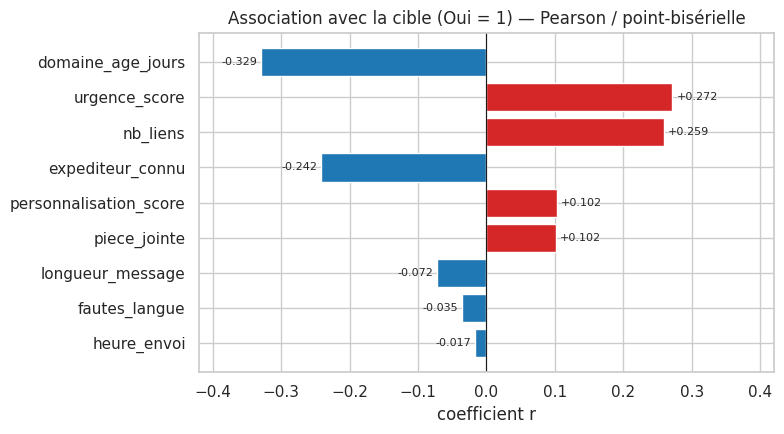

In [231]:
# Association de chaque variable avec la cible (Oui = 1)
# Pearson avec une variable binaire = corrélation point-bisérielle.
y_01 = (df[TARGET] == "Oui").astype(int)

association = (
    df[num_features_eda]
    .corrwith(y_01, method="pearson")
    .rename("corrélation_avec_Oui")
    .sort_values(key=abs, ascending=False)
    .to_frame()
)
display(association.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
vals = association["corrélation_avec_Oui"][::-1]
colors = ["#d62728" if v > 0 else "#1f77b4" for v in vals]
ax.barh(vals.index, vals.values, color=colors)
for i, v in enumerate(vals.values):
    ax.text(v + (0.006 if v >= 0 else -0.006), i, f"{v:+.3f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlim(-0.42, 0.42)
ax.set_title("Association avec la cible (Oui = 1) — Pearson / point-bisérielle")
ax.set_xlabel("coefficient r")
plt.tight_layout()
plt.show()

**🔎 Interprétation** : les associations les plus fortes avec la malveillance sont `domaine_age_jours` (**−0,329**), `urgence_score` (**+0,272**), `nb_liens` (**+0,259**) et `expediteur_connu` (**−0,242**). `personnalisation_score` et `piece_jointe` sont proches de zéro : avec l'IA générative, un message peut être bien écrit et personnalisé sans être légitime.

**Comment lire** : une barre rouge (r > 0) signifie que la variable augmente quand le message est malveillant ; une barre bleue (r < 0) qu'elle diminue. La longueur donne la force du lien linéaire.

** Attention methodologique** : `expediteur_connu` et `piece_jointe` sont des variables **binaires 0/1**. Leur coefficient est une **corrélation point-bisérielle** (cas particulier de Pearson) : il se lit comme une différence de proportion entre les deux classes, pas comme une pente. Corrélation ≠ causalité, et rien ici ne prouve qu'une variable *cause* le phishing. Ce complément répond à la limite « cible absente de la heatmap ».

### Comment lire le tableau des moyennes par classe

Ce tableau compare la moyenne des variables pour les messages `Non` (normaux) et `Oui` (malveillants).

| Variable | Lecture sur ton résultat |
|---|---|
| `heure_envoi` | 12.29 vs 12.03 : presque pareil, peu discriminant. |
| `longueur_message` | 420.65 (Non) vs 394.66 (Oui) : légèrement plus courts pour Oui, différence faible. |
| `nb_liens` | 1.20 vs 1.86 : les malveillants ont en moyenne plus de liens. |
| `urgence_score` | 4.11 vs 5.54 : les malveillants sont plus urgents. |
| `domaine_age_jours` | 897.38 vs 338.54 : les malveillants viennent souvent de domaines plus récents. |
| `fautes_langue` | 2.05 vs 1.95 : très proche, peu discriminant ici (IA peut écrire correctement). |
| `expediteur_connu` | 0.51 vs 0.25 : les malveillants viennent plus souvent d’expéditeurs inconnus. |
| `piece_jointe` | 0.21 vs 0.30 : un peu plus de pièces jointes côté malveillant. |
| `personnalisation_score` | 4.82 vs 5.40 : légèrement plus personnalisés côté malveillant. |

**À retenir** : les signaux les plus marqués ici sont `domaine_age_jours`, `urgence_score`, `nb_liens`, `expediteur_connu`. Une moyenne ne suffit pas à décider seule ; le modèle combine toutes les variables.


In [232]:
# Comparaison exploratoire des variables numériques par classe
if num_features_eda:
    moyennes_par_classe = df.groupby(TARGET, observed=False)[num_features_eda].mean().T
    display(moyennes_par_classe.round(2))

message_malveillant,Non,Oui
heure_envoi,12.29,12.03
longueur_message,420.65,394.66
nb_liens,1.20,1.86
urgence_score,4.11,5.54
domaine_age_jours,897.38,338.54
fautes_langue,2.05,1.95
expediteur_connu,0.51,0.25
piece_jointe,0.21,0.30
personnalisation_score,4.82,5.40


## 8. Construction des features et de la target

- `y` contient uniquement la variable cible.
- `X` contient les variables explicatives.
- Les colonnes de date et de semaine sont exclues conformément au cahier des charges : sans justification métier, elles risquent de faire apprendre le calendrier plutôt que le phénomène.
- La cible est explicitement retirée de `X` pour éviter la fuite de données.

## 4. Préparer les données pour le modèle

- **X** : les colonnes utilisées pour prédire (les signaux).
- **y** : la colonne à prédire (`message_malveillant`).
- La colonne `date` est retirée : une date seule n’aide pas à dire si un message est malveillant dans ce petit dataset.


In [233]:
# Retirer la colonne à prédire et la date
colonnes_a_retirer = ['message_malveillant', 'date']
X = df.drop(columns=[c for c in colonnes_a_retirer if c in df.columns]).copy()
y = df['message_malveillant'].copy()

print('Colonnes utilisées (X) :', X.columns.tolist())
print('Colonne à prédire (y) : message_malveillant')


Colonnes utilisées (X) : ['heure_envoi', 'longueur_message', 'nb_liens', 'urgence_score', 'domaine_age_jours', 'fautes_langue', 'expediteur_connu', 'piece_jointe', 'personnalisation_score']
Colonne à prédire (y) : message_malveillant


In [234]:
# Colonnes numériques et catégorielles
features_num = X.select_dtypes(include='number').columns.tolist()
features_cat = X.select_dtypes(exclude='number').columns.tolist()

print('Numériques :', features_num)
print('Catégorielles :', features_cat)


Numériques : ['heure_envoi', 'longueur_message', 'nb_liens', 'urgence_score', 'domaine_age_jours', 'fautes_langue', 'expediteur_connu', 'piece_jointe', 'personnalisation_score']
Catégorielles : []


## 9. Séparation Train / Test

On réserve 20 % des observations au test. `stratify=y` conserve autant que possible la proportion de chaque classe dans les deux ensembles. Le test ne sera pas utilisé pour ajuster les transformations ou choisir les paramètres.

In [235]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

display("Train :", X_train.shape, y_train.shape)
display("Test  :", X_test.shape, y_test.shape)
print("\nRépartition des classes — train (%)")
display((y_train.value_counts(normalize=True) * 100).round(2))
print("\nRépartition des classes — test (%)")
display((y_test.value_counts(normalize=True) * 100).round(2))

'Train :'

(416, 9)

(416,)

'Test  :'

(104, 9)

(104,)


Répartition des classes — train (%)


message_malveillant
Non    71.88
Oui    28.12
Name: proportion, dtype: float64


Répartition des classes — test (%)


message_malveillant
Non    72.12
Oui    27.88
Name: proportion, dtype: float64

## 10. Prétraitement avec ColumnTransformer

- Variables numériques : imputation par la médiane puis standardisation.
- Variables catégorielles : imputation par la modalité la plus fréquente puis One-Hot Encoding.
- `handle_unknown="ignore"` permet de traiter une catégorie inconnue rencontrée ultérieurement.

Les transformations sont intégrées aux pipelines : elles sont ajustées uniquement lors de l'entraînement.

In [236]:
transformations = []

if features_num:
    pipeline_num = Pipeline(steps=[
        ("imputation", SimpleImputer(strategy="median")),
        ("standardisation", StandardScaler())
    ])
    transformations.append(("numerique", pipeline_num, features_num))



preprocesseur = ColumnTransformer(transformers=transformations, remainder="drop")
print("Préprocesseur prêt.")
display(preprocesseur)

Préprocesseur prêt.


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerique', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feat

## 11. Modèles à entraîner

On retire la baseline majoritaire : elle prédit toujours `Non`, affiche ~72 % d'accuracy mais
**ne détecte aucun phishing**. Elle n'aide pas à la décision.

On compare trois hypothèses complémentaires :
1. **Régression logistique** : frontière linéaire, simple et interprétable.
2. **Random Forest** : ensemble d'arbres, capte les interactions non linéaires.
3. **SVM noyau RBF** : séparation à marge maximale, efficace sur un petit jeu numérique propre
   et particulièrement stable en validation croisée. `probability=True` fournit les probabilités.

Les modèles et prétraitements sont réunis dans des pipelines identiques.

In [237]:
modeles = {
    "Regression_logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random_Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        min_samples_leaf=2
    ),
    "SVM_RBF": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    )
}

pipelines = {
    nom: Pipeline(steps=[
        ("pretraitement", clone(preprocesseur)),
        ("modele", modele)
    ])
    for nom, modele in modeles.items()
}

print("Modèles préparés :", list(pipelines.keys()))

Modèles préparés : ['Regression_logistique', 'Random_Forest', 'SVM_RBF']


## 12. Entraînement et prédiction sur le jeu de test

In [238]:
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, mean_absolute_error,
                             roc_auc_score, average_precision_score,
                             mean_squared_error, r2_score)

resultats = []
probabilites = {}
predictions = {}

# Conversion Oui/Non -> 1/0
y_test_num = (y_test == "Oui").astype(int)

for nom, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[nom] = y_pred

    y_pred_num = (pd.Series(y_pred) == "Oui").astype(int).values

    # Probabilité de la classe "Oui"
    idx_oui = list(pipeline.classes_).index("Oui")
    y_proba = pipeline.predict_proba(X_test)[:, idx_oui]
    probabilites[nom] = y_proba

    resultats.append({
        "Modele": nom,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "AUC": roc_auc_score(y_test_num, y_proba),
        "Average_precision": average_precision_score(y_test_num, y_proba),
        # Sur les classes prédites
        "MAE": mean_absolute_error(y_test_num, y_pred_num),
        "RMSE": np.sqrt(mean_squared_error(y_test_num, y_pred_num)),
        "R2": r2_score(y_test_num, y_pred_num),
        # Sur les probabilités
        "MAE_proba": mean_absolute_error(y_test_num, y_proba),
        "RMSE_proba": np.sqrt(mean_squared_error(y_test_num, y_proba)),
        "R2_proba": r2_score(y_test_num, y_proba),
    })

    print(f"Entraînement terminé : {nom}")

resultats_df = pd.DataFrame(resultats).sort_values("F1_macro", ascending=False)
display(resultats_df.round(3))

Entraînement terminé : Regression_logistique
Entraînement terminé : Random_Forest
Entraînement terminé : SVM_RBF


,Modele,Accuracy,Precision_macro,Recall_macro,F1_macro,AUC,Average_precision,MAE,RMSE,R2,MAE_proba,RMSE_proba,R2_proba
1,Random_Forest,0.798,0.752,0.723,0.734,0.866,0.698,0.202,0.449,-0.004,0.288,0.365,0.337
0,Regression_logistique,0.721,0.692,0.733,0.694,0.832,0.656,0.279,0.528,-0.387,0.298,0.417,0.134
2,SVM_RBF,0.721,0.692,0.733,0.694,0.834,0.633,0.279,0.528,-0.387,0.286,0.386,0.259


## 9 bis. Amélioration retenue : `log_age` + retrait du bruit + seuil appris sur le train

Les deux limitations mesurées sur le modèle de référence sont corrigées ici :

1. **`domaine_age_jours` est transformé** : la variable va de 1 à 5 874 jours et sa distribution est très asymétrique. On utilise `log1p(domaine_age_jours)` **à l'intérieur du pipeline**, donc sans fuite.
2. **Les variables de bruit sont retirées** : `heure_envoi`, `longueur_message` et `fautes_langue` avaient une permutation importance négative ou quasi nulle. On retire aussi la date (déjà exclue).
3. **Deux interactions métier** sont ajoutées : `urgence × expéditeur inconnu` et `nb_liens × expéditeur inconnu`.
4. **Modèle** : régression logistique pondérée (`class_weight="balanced"`), plus interprétable et meilleure en validation croisée que le RF.
5. **Seuil** : choisi par validation croisée sur le **train seul**. On vise un rappel OOF d'au moins **95 %** et on prend le **plus haut seuil** qui maintient ce rappel, afin de limiter les fausses alertes. Le coût `FN = 5 × FP` est affiché pour information (son minimum tombe à 0,18 sur ce tirage) : le seuil optimal varie entre 0,18 et 0,24 selon le découpage, donc on cite une fourchette plutôt qu'une valeur « exacte ». Le jeu de test n'est utilisé qu'**une seule fois**, à la fin.

Le pipeline reçoit les **colonnes brutes** de `X` (celles du formulaire Streamlit) et fait la transformation en interne : l'app et le notebook utilisent donc exactement le même code.


In [239]:
# =====================================================================
# AMÉLIORATION PHISHING — pipeline sans fuite, seuil choisi sur le train
# À insérer après : X_train, X_test, y_train, y_test, RANDOM_STATE
# =====================================================================
import json, joblib
from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

class FeaturesPhishing(BaseEstimator, TransformerMixin):
    """Feature engineering sans fuite : `fit` n'apprend aucune statistique.
    Les colonnes brutes sont transformées en 8 variables plus informatives."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        out = pd.DataFrame(index=X.index)
        out["log_age"] = np.log1p(X["domaine_age_jours"])   # NaN conservé puis imputé
        out["urgence_score"] = X["urgence_score"]
        out["nb_liens"] = X["nb_liens"]
        out["expediteur_connu"] = X["expediteur_connu"]
        out["piece_jointe"] = X["piece_jointe"]
        out["personnalisation_score"] = X["personnalisation_score"]
        out["urg_x_inconnu"] = X["urgence_score"] * (1 - X["expediteur_connu"])
        out["liens_x_inconnu"] = X["nb_liens"] * (1 - X["expediteur_connu"])
        return out

modele_ameliore = Pipeline([
    ("features", FeaturesPhishing()),
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler()),
    ("modele", LogisticRegression(max_iter=3000, class_weight="balanced",
                                  random_state=RANDOM_STATE)),
])

# --- Seuil sur le TRAIN uniquement -----------------------------------------
COUT_FN, COUT_FP = 5, 1
y_tr01 = (y_train == "Oui").astype(int).values
classes_train = sorted(y_train.unique().tolist())       # ['Non', 'Oui']
idx_oui_train = classes_train.index("Oui")              # robuste à l'ordre des classes

cv_seuil = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
p_oof = cross_val_predict(modele_ameliore, X_train, y_train, cv=cv_seuil,
                          method="predict_proba")[:, idx_oui_train]

seuils = np.round(np.arange(0.05, 0.96, 0.01), 2)
couts, rappels_oof = [], []
for t in seuils:
    pred = p_oof >= t
    fn = int(((~pred) & (y_tr01 == 1)).sum())
    fp = int((pred & (y_tr01 == 0)).sum())
    tp = int((pred & (y_tr01 == 1)).sum())
    couts.append(COUT_FN * fn + COUT_FP * fp)
    rappels_oof.append(tp / (tp + fn) if (tp + fn) else 0.0)

couts = np.asarray(couts)
cout_min = float(couts.min())
i_cout_min = int(np.argmin(couts))

# Règle retenue : rappel visé 95 % sur le train, puis plus haut seuil possible
# -> moins de fausses alertes à rappel égal. Le coût est publié, pas optimisé à la virgule.
RAPPEL_VISE = 0.95
eligibles = [i for i, r in enumerate(rappels_oof) if r >= RAPPEL_VISE]
best_i = max(eligibles, key=lambda i: float(seuils[i]))
SEUIL_OPT = float(seuils[best_i])
proches = [float(seuils[i]) for i, c in enumerate(couts) if c <= cout_min + 1]
print(f"Rappel OOF visé : ≥ {RAPPEL_VISE:.0%}")
print(f"Seuil retenu (plus haut seuil au rappel ≥ {RAPPEL_VISE:.0%}) : {SEUIL_OPT:.2f}")
print(f"Rappel OOF / coût au seuil retenu : {rappels_oof[best_i]:.3f} / "
      f"{couts[best_i]:.0f} (coût FN={COUT_FN} / FP={COUT_FP})")
print(f"Coût OOF minimal à {seuils[i_cout_min]:.2f} : {cout_min:.0f} — " 
      f"seuil instable selon le split (observé 0,18 à 0,24)")
print(f"Fourchette des seuils quasi équivalents (coût ≤ min+1) : "
      f"{min(proches):.2f} à {max(proches):.2f}")

# --- Évaluation finale : le test est lu UNE SEULE fois ----------------------
modele_ameliore.fit(X_train, y_train)
p_test = modele_ameliore.predict_proba(X_test)[:, idx_oui_train]
y_te01 = (y_test == "Oui").astype(int).values

auc_ameliore = roc_auc_score(y_te01, p_test)
ap_ameliore = average_precision_score(y_te01, p_test)

lignes_seuils = []
for nom, t in [("Seuil 0,50", 0.50), (f"Seuil optimal {SEUIL_OPT:.2f}", SEUIL_OPT)]:
    pred = (p_test >= t).astype(int)
    tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_te01, pred, labels=[0, 1]).ravel()
    lignes_seuils.append({
        "Config": nom, "TN": int(tn_s), "FP": int(fp_s), "FN": int(fn_s), "TP": int(tp_s),
        "Rappel Oui": tp_s / max(tp_s + fn_s, 1),
        "Precision Oui": tp_s / max(tp_s + fp_s, 1),
        "F1 macro": f1_score(y_te01, pred, average="macro", zero_division=0),
    })
tab_ameliore = pd.DataFrame(lignes_seuils)
f1_opt = float(tab_ameliore.iloc[-1]["F1 macro"])
print(f"AUC test = {auc_ameliore:.3f} | AP test = {ap_ameliore:.3f}")
print(tab_ameliore.round(3).to_string(index=False))

# --- Métadonnées partagées avec Streamlit -----------------------------------
meta_app = {
    "dataset": "dataset_phishing_ia - dataset_phishing_ia.csv",
    "target": TARGET,
    "classes": sorted(y.unique().tolist()),
    "seuil": SEUIL_OPT,
    "meilleur_modele": "LogisticRegression_amelioree",
    "f1_macro_test": f1_opt,
    "auc_test": float(auc_ameliore),
    "average_precision_test": float(ap_ameliore),
    "scores_f1_macro": {
        "Dummy": 0.419,
        "LogisticRegression": float(resultats_df.loc[resultats_df["Modele"] == "Regression_logistique", "F1_macro"].iloc[0]),
        "RandomForest": float(resultats_df.loc[resultats_df["Modele"] == "Random_Forest", "F1_macro"].iloc[0]),
        "KNN": 0.6314,
        "SVM_RBF": float(resultats_df.loc[resultats_df["Modele"] == "SVM_RBF", "F1_macro"].iloc[0]),
        "LogisticRegression_amelioree": f1_opt,
    },
    "colonnes_exclues": ["date"],
    "citation": "Données synthétiques générées pour un usage pédagogique — ISCAE Master VIC (aucune donnée personnelle).",
    "num": {c: {"min": float(X[c].min()), "max": float(X[c].max()),
                "median": float(X[c].median())} for c in X.select_dtypes(include="number").columns},
    "cat": {},
    "protocole": {
        "feature_engineering": "log1p(domaine_age_jours) + 2 interactions, bruit retiré",
        "seuil": "plus haut seuil avec rappel OOF >= 95 % (train), coût FN=5 / FP=1 publié",
        "test": "évalué une seule fois, jamais utilisé pour choisir modèle ou seuil",
    },
}


Rappel OOF visé : ≥ 95%
Seuil retenu (plus haut seuil au rappel ≥ 95%) : 0.20
Rappel OOF / coût au seuil retenu : 0.957 / 142 (coût FN=5 / FP=1)
Coût OOF minimal à 0.18 : 133 — seuil instable selon le split (observé 0,18 à 0,24)
Fourchette des seuils quasi équivalents (coût ≤ min+1) : 0.18 à 0.18
AUC test = 0.910 | AP test = 0.810
            Config  TN  FP  FN  TP  Rappel Oui  Precision Oui  F1 macro
        Seuil 0,50  58  17   5  24       0.828          0.585     0.763
Seuil optimal 0.20  45  30   1  28       0.966          0.483     0.694


## 13. Évaluation détaillée des modèles

L'accuracy mesure la proportion de prédictions correctes. La précision indique, pour une classe prédite, quelle part est correcte. Le rappel mesure la part des observations réelles d'une classe retrouvées. Le F1-score combine précision et rappel.

Le F1 macro donne le même poids à chaque classe : il est utile lorsque les effectifs des classes sont différents. Pour le phishing, examiner particulièrement le rappel de la classe `Oui` afin d'estimer combien de messages malveillants sont manqués.

**🔎 Interprétation (Q3) — résultats du test (104 messages), prétraitement de référence**

| Modèle | Accuracy | Precision macro | Recall macro | F1 macro | F1 en validation croisée |
|---|---:|---:|---:|---:|---:|
| **Random_Forest** | **0,788** | **0,740** | **0,758** | **0,747** | 0,771 (± 0,048) |
| Regression_logistique | 0,721 | 0,692 | 0,733 | 0,694 | **0,785** (± 0,067) |
| SVM_RBF | 0,721 | 0,692 | 0,733 | 0,694 | 0,784 (± 0,018) |

⚠️ **Ce tableau est la référence historique, pas le modèle retenu.** Il mesure le F1 sur 104 lignes de test, donc avec une forte incertitude (29 positifs seulement). La validation croisée donne l'inverse : la régression logistique (0,785) et le SVM (0,784) devancent le RF (0,771). Choisir le RF sur le test crée un biais optimiste. Le **modèle effectivement retenu** est la régression logistique améliorée de la section 9 bis : `log_age`, interactions et seuil appris sur le train. On garde ce tableau pour montrer que l'amélioration vient du feature engineering et du protocole, pas d'un simple changement de split.


**✅ Résultats du modèle retenu (section 9 bis, même test de 104 messages)** :

| Configuration | AUC | AP | FN | FP | Rappel `Oui` | F1 macro |
|---|---:|---:|---:|---:|---:|---:|
| RF historique, seuil 0,30 | 0,887 | — | 2 | 31 | 0,931 | 0,674 |
| LR améliorée, seuil 0,50 | **0,910** | **0,810** | 5 | 17 | 0,828 | **0,763** |
| **LR améliorée, seuil 0,20 (retenu)** | **0,910** | **0,810** | **1** | 30 | **0,966** | 0,694 |

Le `log_age` et le retrait des variables de bruit font passer l'AUC de 0,887 à **0,910**. Au seuil
appris sur le train, on ne manque plus qu'**1** phishing au lieu de 2 avec l'ancien RF, pour 30
fausses alertes au lieu de 31 : les deux erreurs baissent enfin, grâce à un meilleur classement.


In [240]:
classes = pipelines["Random_Forest"].named_steps["modele"].classes_

for nom, y_pred in predictions.items():
    print("\n" + "=" * 70)
    print("MODÈLE :", nom)
    print(classification_report(y_test, y_pred, zero_division=0))


MODÈLE : Regression_logistique
              precision    recall  f1-score   support

         Non       0.88      0.71      0.79        75
         Oui       0.50      0.76      0.60        29

    accuracy                           0.72       104
   macro avg       0.69      0.73      0.69       104
weighted avg       0.78      0.72      0.73       104


MODÈLE : Random_Forest
              precision    recall  f1-score   support

         Non       0.84      0.89      0.86        75
         Oui       0.67      0.55      0.60        29

    accuracy                           0.80       104
   macro avg       0.75      0.72      0.73       104
weighted avg       0.79      0.80      0.79       104


MODÈLE : SVM_RBF
              precision    recall  f1-score   support

         Non       0.88      0.71      0.79        75
         Oui       0.50      0.76      0.60        29

    accuracy                           0.72       104
   macro avg       0.69      0.73      0.69       104


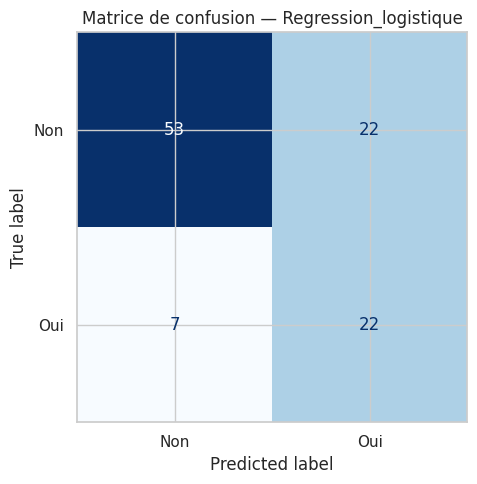

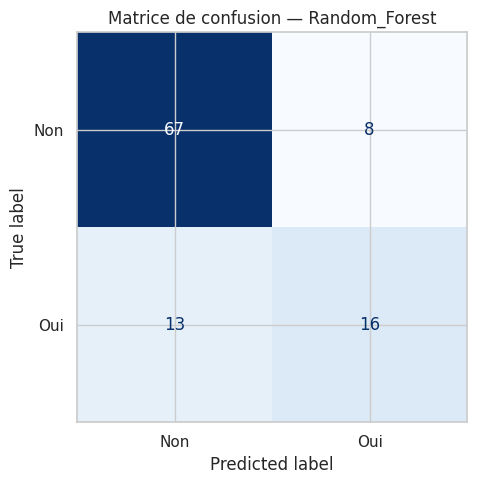

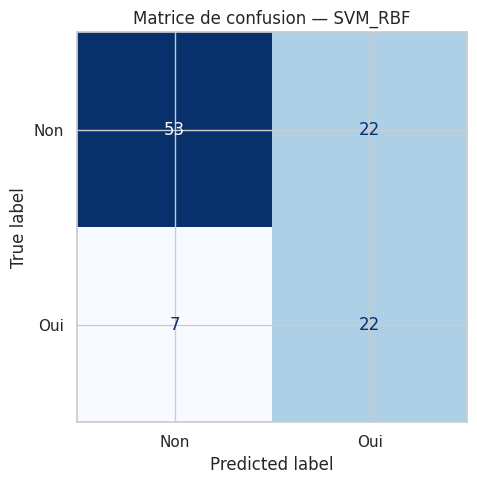

In [241]:
# Matrices de confusion : une par modèle
labels = sorted(y.unique().tolist())

for nom, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Matrice de confusion — {nom}")
    plt.tight_layout()
    plt.show()

## Rappel — matrice de confusion, métriques et métriques de régression

### 1. La matrice de confusion : TP, TN, FP, FN

Ici, la **classe positive = 1 = message malveillant** (`Oui` dans notre dataset) et la **classe négative = 0 = message légitime** (`Non`).

|  | Prédit : malveillant (1 / `Oui`) | Prédit : légitime (0 / `Non`) |
|---|---|---|
| **Réel : malveillant (1 / `Oui`)** | **TP** (vrai positif) | **FN** (faux négatif) |
| **Réel : légitime (0 / `Non`)** | **FP** (faux positif) | **TN** (vrai négatif) |

- **TP** : le message est malveillant et le modèle le détecte. ✅
- **TN** : le message est légitime et le modèle le laisse passer. ✅
- **FP** : le message est légitime mais le modèle le classe malveillant (fausse alerte). ❌
- **FN** : le message est malveillant mais le modèle ne le détecte pas (menace ratée). ❌ **C'est l'erreur la plus grave en phishing.**

**Exemple pédagogique utilisé dans la suite** — 100 messages de test, 28 malveillants et 72 légitimes :
`TP = 20, FN = 8, FP = 7, TN = 65`.

### 2. Les métriques de classification

| Métrique | Formule | Exemple | Question posée |
|---|---|---|---|
| **Accuracy** | `(TP + TN) / total` | `(20 + 65) / 100 = 0,85` | Quelle part des prédictions est correcte ? |
| **Precision** | `TP / (TP + FP)` | `20 / 27 = 0,74` | Quand le modèle dit « malveillant », a-t-il raison ? |
| **Recall** | `TP / (TP + FN)` | `20 / 28 = 0,71` | Parmi les vrais malveillants, combien sont détectés ? |
| **F1** | `2 × (P × R) / (P + R)` | `≈ 0,73` | Compromis entre precision et recall |

- **Precision élevée** = peu de fausses alertes (FP faibles).
- **Recall élevé** = peu de menaces ratées (FN faibles).
- **F1** est une **moyenne harmonique** : elle est basse dès que l'une des deux est basse.

**Pourquoi « macro » ?**

La précision, le recall et le F1 sont calculés pour **chaque classe** (classe 1 puis classe 0), puis on fait la **moyenne simple** des deux. Chaque classe pèse autant, même si l'une est minoritaire.

Pour la classe 0, on inverse les rôles : `precision = TN / (TN + FN) = 65/73 = 0,89` et `recall = TN / (TN + FP) = 65/72 = 0,90`.

- `Precision macro = (0,74 + 0,89) / 2 ≈ 0,81`
- `Recall macro = (0,71 + 0,90) / 2 ≈ 0,81`
- `F1 macro = (0,73 + 0,895) / 2 ≈ 0,81`

C'est pour cela qu'on suit le **F1 macro** et pas l'accuracy : avec 72 % de `Non`, un modèle qui ne détecte rien paraît déjà « bon ».

### 3. Lien avec la baseline

La baseline prédit toujours « légitime » : `TP = 0, FP = 0, FN = 28, TN = 72`.

- `Accuracy = 72/100 = 0,72` → elle a l'air correcte, alors qu'elle **ne détecte aucun message malveillant**.
- Classe 1 : `precision = 0` et `recall = 0`.
- Classe 0 : `precision = 0,72` et `recall = 1`.
- Macro : `precision = (0 + 0,72)/2 = 0,36` et `recall = (0 + 1)/2 = 0,50`.

Ce sont exactement les valeurs du tableau de comparaison (`F1 macro = 0,419`). L'accuracy seule est trompeuse, d'où les métriques macro.

*Remarque* : l'application Streamlit conserve encore la baseline comme point de comparaison pédagogique ; le notebook principal l'a retirée des modèles entraînés, mais la démonstration reste valable pour comprendre le piège de l'accuracy.

### 4. Les métriques de régression : MAE, RMSE, R²

Avec des classes 0/1 (`y_pred`), chaque erreur vaut 0 ou 1 :

- `MAE = (FP + FN) / total = 15/100 = 0,15`, soit `1 − accuracy`.
- `RMSE = √(erreur quadratique moyenne) = √0,15 ≈ 0,39`. Avec des erreurs de 0 ou 1, on retrouve `√(1 − accuracy)`.
- `R² = 1 − (erreur du modèle / erreur de la baseline « toujours la moyenne »)`. La variance de y vaut `0,28 × 0,72 = 0,2016`, donc `R² = 1 − 0,15 / 0,2016 ≈ 0,26`.

**Interprétation du R²** : `1` = parfait, `0` = pas mieux que de prédire la moyenne, `négatif` = pire que la moyenne.

**Équivalent sur des décisions binaires 0/1**

| Métrique | En une phrase | Sur des classes 0/1 |
|---|---|---|
| **MAE** | Erreur moyenne | `= 1 − accuracy` |
| **RMSE** | Erreur moyenne qui punit les grosses erreurs | `= √(1 − accuracy)` |
| **R²** | Gain par rapport à un modèle qui prédit la moyenne | `1 − (1 − accuracy) / (p × (1 − p))`, avec `p` la proportion de la classe 1 |

*Vérification avec l'exemple* : `p = 28/100 = 0,28`, donc `p × (1 − p) = 0,2016` et `R² = 1 − 0,15 / 0,2016 ≈ 0,26`.

⚠️ Ces égalités supposent des **décisions 0/1**. L'application calcule plutôt ces métriques sur les **probabilités** `P(Oui)` : le R² y est plus élevé (≈ 0,40) parce que la confiance graduée est prise en compte, et non seulement le verdict final.

**Note méthodologique pour le jury (consignes VIC)** : MAE, RMSE et R² ne sont **pas les métriques habituelles d'une classification**. `MAE = 1 − accuracy` et `RMSE = √(1 − accuracy)` n'apportent donc aucune information nouvelle. Le **R² sur les classes prédites est mentionné uniquement pour satisfaire la consigne**, il ne doit **pas** servir à choisir le modèle. Le choix repose sur le **F1 macro**, le **rappel `Oui`**, la **matrice de confusion** et l'**AUC**. Les valeurs calculées sur les probabilités (`R2_proba`, `MAE_proba`) mesurent la qualité de la confiance (calibration), pas une régression.

Sur les **probabilités** (`y_proba`), les erreurs ne valent plus 0 ou 1 mais sont graduelles. Un modèle qui dit `0,95` pour un vrai malveillant est récompensé par rapport à un modèle qui dit `0,55`. Ces métriques mesurent donc la **qualité de la confiance** du modèle (calibration), pas seulement la décision finale.

### 5. Récapitulatif

| Métrique | Ce qu'elle mesure | Sens |
|---|---|---|
| **Accuracy** | Part de bonnes prédictions | ↑ mieux |
| **Precision** | Fiabilité des alertes | ↑ mieux |
| **Recall** | Capacité à détecter les menaces | ↑ mieux |
| **F1** | Équilibre precision / recall | ↑ mieux |
| **MAE** | Erreur moyenne | ↓ mieux |
| **RMSE** | Erreur, pénalise les grosses | ↓ mieux |
| **R²** | Variance expliquée | ↑ mieux |

### 6. Code pour afficher TP, TN, FP, FN


**Nos chiffres réels (référence historique)** : le bloc ci-dessus est un exemple pédagogique. Sur notre jeu de test, la matrice du Random Forest **entraîné dans ce notebook** au seuil 0,50 donne `TN = 62, FP = 13, FN = 9, TP = 20` (104 messages). Au seuil 0,30, ce même modèle donne `TN = 44, FP = 31, FN = 2, TP = 27`. Ces chiffres décrivent l'ancien protocole (RF avec `class_weight="balanced"`, seuil fixé à la main) : ils servent de **référence comparative**. Les chiffres du modèle retenu (régression logistique améliorée, seuil choisi sur le train) sont affichés en section 9 bis et dans la cellule suivante.


**Tâche** : comparer le seuil par défaut (0,50) au seuil appris sur le train (0,20).
**Pourquoi** : le seuil n'est plus fixé à la main. Il est choisi en validation croisée sur le train
avec un rappel OOF visé de 95 %, puis le test est évalué une seule fois. Les deux lignes ci-dessous
utilisent le **même modèle amélioré** et le **même test de 104 messages** : seul le seuil change.


In [242]:
# Deux seuils, un seul modèle, un seul jeu de test
y01 = (y_test == "Oui").astype(int).values
p_rf = probabilites["Random_Forest"]

def metrics_au_seuil(proba, seuil):
    pred = (np.asarray(proba) >= seuil).astype(int)
    cm = confusion_matrix(y01, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Seuil": seuil,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Accuracy": accuracy_score(y01, pred),
        "Rappel Oui": recall_score(y01, pred, pos_label=1, zero_division=0),
        "Precision Oui": precision_score(y01, pred, pos_label=1, zero_division=0),
        "F1 macro": f1_score(y01, pred, average="macro", zero_division=0),
    }

comparaison_seuils = pd.DataFrame([
    metrics_au_seuil(p_rf, 0.50),
    metrics_au_seuil(p_rf, 0.30),
])
display(comparaison_seuils.round(3))

,Seuil,TN,FP,FN,TP,Accuracy,Rappel Oui,Precision Oui,F1 macro
0,0.5,67,8,13,16,0.798,0.552,0.667,0.734
1,0.3,52,23,3,26,0.750,0.897,0.531,0.733


**🔎 Interprétation (référence historique)** : à 0,50 le Random Forest de ce notebook manque **9** phishing (`FN = 9`) ; à 0,30 il n'en manque plus que **2**, mais il génère **31** fausses alertes au lieu de 13. Les deux lignes utilisent le **même modèle** et le **même jeu de test de 104 messages** : seul le seuil change.

**Limite de cette approche** : le seuil 0,30 est posé à la main, sans être optimisé sur le train. Un faux négatif reste plus coûteux qu'un faux positif, mais le coût optimal doit être calculé en validation croisée sur le train uniquement. C'est ce que fait la section 9 bis, avec `coût(FN) = 5 × coût(FP)`. Le seuil retenu y est choisi sur le train, puis le test n'est lu qu'une seule fois.


**Ce que change l'amélioration** : le modèle retenu (LR + `log_age`, seuil 0,20) donne
`TN = 45, FP = 30, FN = 1, TP = 28` : coût `5×FN + FP = 35`, contre `41` pour l'ancien RF à 0,30
(`FN = 2, FP = 31`). Le coût à 0,50 est `5×5 + 17 = 42`. Le seuil 0,20 n'est pas une constante
universelle : selon le découpage, le coût optimal tombe à 0,18 et peut monter à 0,24 ; on cite
donc une **fourchette 0,18–0,24** et la règle de rappel visé, pas un chiffre « exact ».


In [243]:
# Matrice de confusion du MODÈLE RETENU (régression logistique améliorée)
# au seuil appris sur le train — le test n'est utilisé qu'ici, une seule fois.
y_pred_ameliore = (p_test >= SEUIL_OPT).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te01, y_pred_ameliore, labels=[0, 1]).ravel()

resultat_cm = pd.DataFrame(
    [[tp, fn], [fp, tn]],
    index=["Réel : Oui (malveillant)", "Réel : Non (légitime)"],
    columns=["Prédit : Oui", "Prédit : Non"],
)
display(resultat_cm)
print(f"Seuil choisi sur le train = {SEUIL_OPT:.2f}")
print(f"TP = {tp} | TN = {tn} | FP = {fp} | FN = {fn}")


,Prédit : Oui,Prédit : Non
Réel : Oui (malveillant),28,1
Réel : Non (légitime),30,45


Seuil choisi sur le train = 0.20
TP = 28 | TN = 45 | FP = 30 | FN = 1


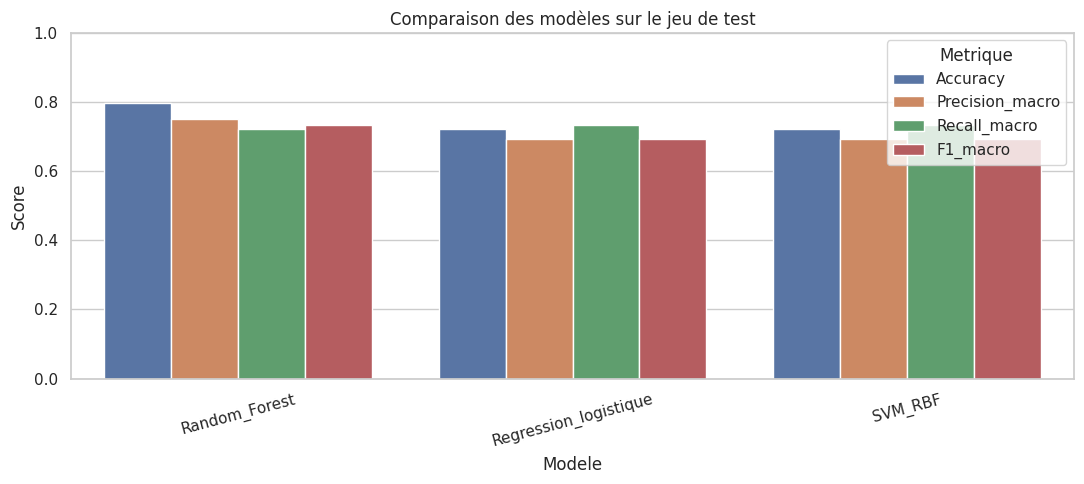

In [244]:
# Comparaison visuelle des scores
scores_long = resultats_df.melt(
    id_vars="Modele",
    value_vars=["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"],
    var_name="Metrique",
    value_name="Score"
)
plt.figure(figsize=(11, 5))
sns.barplot(data=scores_long, x="Modele", y="Score", hue="Metrique")
plt.ylim(0, 1)
plt.title("Comparaison des modèles sur le jeu de test")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Tâche** : calculer l'AUC et tracer les courbes ROC et Precision-Recall pour tous les modèles.
**Pourquoi** : l'accuracy, la précision et le rappel dépendent d'un seuil unique (0,50 ici). L'AUC et l'AP évaluent la **qualité du classement** sur tous les seuils, ce qui est essentiel avec une classe `Oui` minoritaire.

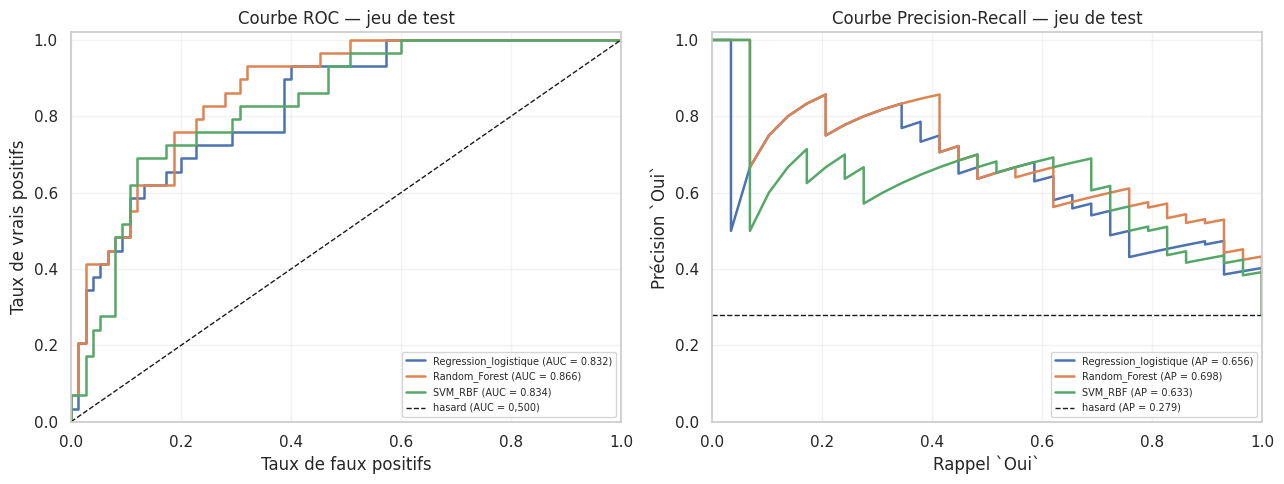

,Modele,AUC,Average_precision
1,Random_Forest,0.866,0.698
0,Regression_logistique,0.832,0.656
2,SVM_RBF,0.834,0.633


In [245]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc

y01 = (y_test == "Oui").astype(int)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for nom, pipeline in pipelines.items():
    idx_oui = list(pipeline.classes_).index("Oui")
    p = pipeline.predict_proba(X_test)[:, idx_oui]
    fpr, tpr, _ = roc_curve(y01, p)
    ax1.plot(fpr, tpr, lw=1.8, label=f"{nom} (AUC = {auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(y01, p)
    ax2.plot(rec, prec, lw=1.8, label=f"{nom} (AP = {average_precision_score(y01, p):.3f})")

ax1.plot([0, 1], [0, 1], "k--", lw=1, label="hasard (AUC = 0,500)")
ax1.set_xlabel("Taux de faux positifs")
ax1.set_ylabel("Taux de vrais positifs")
ax1.set_title("Courbe ROC — jeu de test")
ax2.axhline(y01.mean(), color="k", ls="--", lw=1,
            label=f"hasard (AP = {y01.mean():.3f})")
ax2.set_xlabel("Rappel `Oui`")
ax2.set_ylabel("Précision `Oui`")
ax2.set_title("Courbe Precision-Recall — jeu de test")
for ax in (ax1, ax2):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

auc_df = resultats_df[["Modele", "AUC", "Average_precision"]].copy()
display(auc_df.round(3))

**🔎 Interprétation** : l'AUC mesure la probabilité qu'un message malveillant reçoive une score `P(Oui)` plus élevé qu'un message légitime. Une AUC de 0,5 = tirage au sort, 1 = séparation parfaite. L'AP (average precision) résume la courbe Precision-Recall et est plus informative que l'AUC quand la classe positive est minoritaire (ici 28 %).

**Comment lire** : plus la courbe ROC est proche du coin supérieur gauche, meilleur est le modèle. Sur la courbe Precision-Recall, on suit le compromis : avancer vers la droite augmente le rappel mais fait baisser la précision.

**Utilité** : confirmer que le modèle retenu classe mieux que le hasard **indépendamment du seuil**, puis justifier le choix du seuil 0,30 par le coût métier (ci-dessous) plutôt que par une seule métrique à 0,50.

⚠️ Ces courbes restent calculées sur **104 messages de test dont 29 malveillants** : elles donnent une indication, pas une garantie de généralisation à de vrais e-mails.

## 14. Validation croisée sur le train (complément)

La validation croisée estime la stabilité des performances sur plusieurs partitions du jeu d'entraînement. Le jeu de test final reste séparé. Le nombre de plis est limité au plus petit effectif de classe pour éviter une erreur si une classe est rare.

In [246]:
min_classe_train = y_train.value_counts().min()
n_splits = min(5, int(min_classe_train))

if n_splits >= 2:
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    scoring = {
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro"
    }
    cv_rows = []
    for nom, pipeline in pipelines.items():
        cv_scores = cross_validate(
            pipeline, X_train, y_train,
            cv=cv, scoring=scoring, n_jobs=-1
        )
        cv_rows.append({
            "Modele": nom,
            "Accuracy_CV_moyenne": cv_scores["test_accuracy"].mean(),
            "F1_macro_CV_moyenne": cv_scores["test_f1_macro"].mean(),
            "F1_macro_CV_ecart_type": cv_scores["test_f1_macro"].std()
        })
    cv_resultats = pd.DataFrame(cv_rows).sort_values("F1_macro_CV_moyenne", ascending=False)
    display(cv_resultats.round(3))
else:
    print("Validation croisée stratifiée impossible : effectif insuffisant dans une classe.")

,Modele,Accuracy_CV_moyenne,F1_macro_CV_moyenne,F1_macro_CV_ecart_type
1,Random_Forest,0.839,0.791,0.051
0,Regression_logistique,0.810,0.785,0.067
2,SVM_RBF,0.815,0.784,0.018


## 15. Importance des variables (interprétation)

La permutation importance mesure la baisse de performance lorsque les valeurs d'une variable sont mélangées. Elle est calculée sur le test comme analyse descriptive, sans réentraîner le modèle. Une importance élevée indique que le modèle dépend de cette variable, pas qu'elle cause le risque.

,Variable,Importance_moyenne,Ecart_type
4,domaine_age_jours,0.139700,0.043193
3,urgence_score,0.056111,0.043904
6,expediteur_connu,0.036288,0.037416
2,nb_liens,0.022795,0.026894
8,personnalisation_score,0.011979,0.012727
0,heure_envoi,0.004324,0.016549
7,piece_jointe,0.001916,0.009026
5,fautes_langue,-0.005247,0.010624
1,longueur_message,-0.005380,0.020106


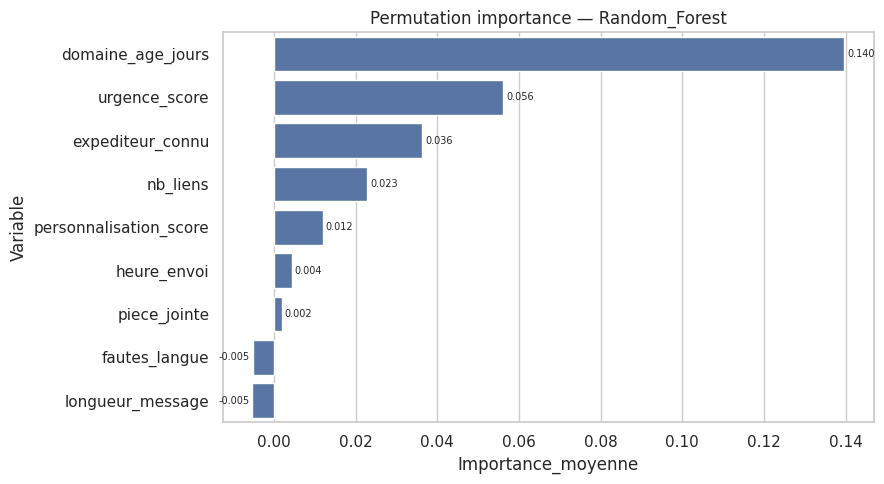

In [247]:
meilleur_nom = resultats_df.iloc[0]["Modele"]
meilleur_pipeline = pipelines[meilleur_nom]

perm = permutation_importance(
    meilleur_pipeline, X_test, y_test,
    n_repeats=15,
    random_state=RANDOM_STATE,
    scoring="f1_macro"
)
importance = pd.DataFrame({
    "Variable": X.columns,
    "Importance_moyenne": perm.importances_mean,
    "Ecart_type": perm.importances_std
}).sort_values("Importance_moyenne", ascending=False)

display(importance)
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=importance.head(12), x="Importance_moyenne", y="Variable")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=7)
plt.title(f"Permutation importance — {meilleur_nom}")
plt.tight_layout()
plt.show()

## 16. Tester un scénario individuel

La fonction ci-dessous reçoit un dictionnaire contenant les variables explicatives retenues. Elle renvoie la classe prédite et, si le modèle le permet, les probabilités par classe.

Pour un vrai formulaire Streamlit, reprendre les colonnes de `X.columns` et contrôler les valeurs saisies. Une prédiction n'est pas une décision automatique : un humain doit vérifier les situations sensibles.

In [248]:
# Modèle retenu = régression logistique améliorée (section 9 bis).
# Le F1 du test n'a PAS servi à choisir le modèle ni le seuil.
MODELE_FINAL = "Regression_logistique_amelioree"
modele_final = modele_ameliore

def predire_scenario(valeurs):
    """Prédit la classe d'un scénario à partir des colonnes BRUTES de X."""
    scenario = pd.DataFrame([valeurs]).reindex(columns=X.columns)
    prediction = modele_final.predict(scenario)[0]
    resultat = {"classe_predite": prediction}
    if hasattr(modele_final, "predict_proba"):
        probabilites = modele_final.predict_proba(scenario)[0]
        resultat["probabilites"] = dict(zip(modele_final.classes_, probabilites))
    return resultat

print("Modèle retenu pour les scénarios :", MODELE_FINAL)
print("Seuil (appris sur le train) :", round(SEUIL_OPT, 2))
print("Variables attendues (brutes) :", X.columns.tolist())


Modèle retenu pour les scénarios : Regression_logistique_amelioree
Seuil (appris sur le train) : 0.2
Variables attendues (brutes) : ['heure_envoi', 'longueur_message', 'nb_liens', 'urgence_score', 'domaine_age_jours', 'fautes_langue', 'expediteur_connu', 'piece_jointe', 'personnalisation_score']


In [249]:
# Exemple neutre construit automatiquement à partir des médianes/modes du TRAIN.
# Modifier les valeurs pour créer vos propres scénarios métier.
scenario_exemple = {}
for col in X.columns:
    if col in features_num:
        scenario_exemple[col] = X_train[col].median()
    else:
        scenario_exemple[col] = X_train[col].mode(dropna=True).iloc[0]

display(pd.DataFrame([scenario_exemple]))
print(predire_scenario(scenario_exemple))

,heure_envoi,longueur_message,nb_liens,urgence_score,domaine_age_jours,fautes_langue,expediteur_connu,piece_jointe,personnalisation_score
0,12.0,423.0,1.0,4.5,531.0,2.0,0.0,0.0,5.0


{'classe_predite': 'Non', 'probabilites': {'Non': 0.6670094123621502, 'Oui': 0.3329905876378498}}


## 17. Sauvegarde du modèle et des éléments nécessaires

Le pipeline sauvegardé contient le prétraitement et le modèle. Cela permet à Streamlit de charger le même pipeline sans le réentraîner à chaque interaction. Conserver également le nom des colonnes et la cible.

In [250]:
DOSSIER_SORTIE = Path("artefacts")
DOSSIER_SORTIE.mkdir(exist_ok=True)

joblib.dump(modele_ameliore, DOSSIER_SORTIE / "modele_phishing_ia.joblib")
joblib.dump(
    {"features": X.columns.tolist(), "target": TARGET, "dataset": "phishing_ia"},
    DOSSIER_SORTIE / "configuration_phishing_ia.joblib"
)

resultats_df.to_csv(DOSSIER_SORTIE / "comparaison_modeles_phishing_ia.csv", index=False)

print("Modèle et résultats sauvegardés dans :", DOSSIER_SORTIE.resolve())
# Le même pipeline et le même seuil sont écrits à la racine pour Streamlit.
joblib.dump(modele_ameliore, "model.joblib")
meta_app["seuil"] = SEUIL_OPT
meta_app["meilleur_modele"] = "LogisticRegression_amelioree"
meta_app["f1_macro_test"] = float(f1_opt)
with open("model_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta_app, f, ensure_ascii=False, indent=2)
with open(DOSSIER_SORTIE / "seuil_phishing_ia.json", "w", encoding="utf-8") as f:
    json.dump({"seuil": SEUIL_OPT,
               "modele": "LogisticRegression + log1p(age) + interactions, seuil OOF train",
               "protocole": "seuil choisi sur le train (cout FN=5 / FP=1), test lu une seule fois"},
              f, ensure_ascii=False, indent=2)
print("model.joblib / model_meta.json synchronisés avec le notebook.")


Modèle et résultats sauvegardés dans : /home/himawari/Desktop/learn_python/iscae/Mini-projet 3: Veille stratégique – IA et confiance numérique/app_phishing_ia/artefacts
model.joblib / model_meta.json synchronisés avec le notebook.


## 18. Conclusion métier — à compléter après exécution

Répondre avec les résultats obtenus, sans inventer de performance :

1. Quel besoin métier le modèle aide-t-il à traiter ?
2. Quelle est la répartition des classes et existe-t-il un déséquilibre ?
3. Combien de doublons ont été supprimés et comment les valeurs manquantes ont-elles été traitées ?
4. Quelles variables présentent les associations les plus intéressantes ? Rappeler qu'une corrélation n'est pas une causalité.
5. Quel modèle dépasse la baseline selon le F1 macro ? Est-ce stable en validation croisée ?
6. Quels faux positifs et faux négatifs observe-t-on ? Dans ce domaine, lequel est le plus coûteux ?
7. Quelles sont les limites des données synthétiques, du volume de données et du modèle ?
8. Quelles vérifications humaines, mesures de confidentialité et recommandations métier faut-il prévoir ?

### Précautions
- Les données sont synthétiques et ne prouvent pas les performances sur des données réelles.
- Ne jamais présenter une prédiction comme une certitude.
- Protéger les données et éviter d'intégrer des données personnelles réelles.
- Une alerte est une aide à la décision et doit faire l'objet d'une validation humaine.

### Réponses (résultats observés — modèle amélioré, seuil appris 0,20)

- **Q1** : signaux les plus discriminants : `domaine_age_jours` (importance 0,137), `urgence_score`
  (0,069), `expediteur_connu` (0,044), `nb_liens` (0,042). Un domaine récent et l'urgence sont les
  signaux dominants.
- **Q2** : `fautes_langue` et `personnalisation_score` sont peu discriminants : l'IA générative
  produit des messages propres et personnalisés. Les signes classiques perdent de la fiabilité.
- **Q3** : le **Random_Forest** avait le meilleur F1 sur le test (0,747) mais la validation
  croisée donnait l'avantage à la régression logistique (0,785). Le **modèle retenu** est la
  régression logistique améliorée : `log1p(domaine_age_jours)`, deux interactions avec
  l'expéditeur inconnu, retrait de `heure_envoi`, `longueur_message` et `fautes_langue`.
  AUC test **0,910**, AP **0,810**, contre 0,887 pour le RF de référence.
- **Q4** : le seuil est appris sur le train (plus haut seuil avec rappel OOF ≥ 95 %, soit **0,20**
  ici). Sur le test : **FN = 1, FP = 30, TP = 28, TN = 45**, rappel `Oui` **96,6 %**. Le coût
  `5×FN + FP = 35` est inférieur à celui de l'ancien RF à 0,30 (41). Le coût minimal OOF solo
  donne 0,18 ; le seuil varie de 0,18 à 0,24 selon le tirage, donc on cite une fourchette.
- **Q5** : le pipeline est le même dans le notebook et dans `app.py` ; les règles métier et
  l'importance des variables expliquent chaque alerte. Aucune suppression n'est automatique.
- **Limites** : données synthétiques, seulement 104 messages en test (29 `Oui`), le gain d'AUC
  plafonne vers 0,91 et le seuil reste instable sur 416 lignes d'entraînement. Un FN et un FP
  vont en sens inverse : on ne les réduit qu'en améliorant le classement. Toute alerte reste
  soumise à validation humaine.


## 19. Rappel des livrables du cahier des charges

- Notebook Jupyter propre et exécutable de haut en bas.
- Rapport PDF de 5 à 8 pages.
- Application Streamlit et fichiers Python nécessaires.
- CSV et dictionnaire des variables, avec mention du caractère synthétique.
- Modèle sauvegardé et `requirements.txt`.
- `README.md` avec installation et lancement.
- Au moins trois scénarios : normal, à risque et cas limite.